In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import time # para obter seed a cada run no método init_run, comentdo para uso de seed fixa igual a 42
from abc import  ABC,abstractmethod

# 1.0 - Projeto das Classes usando o Padrão Strategy

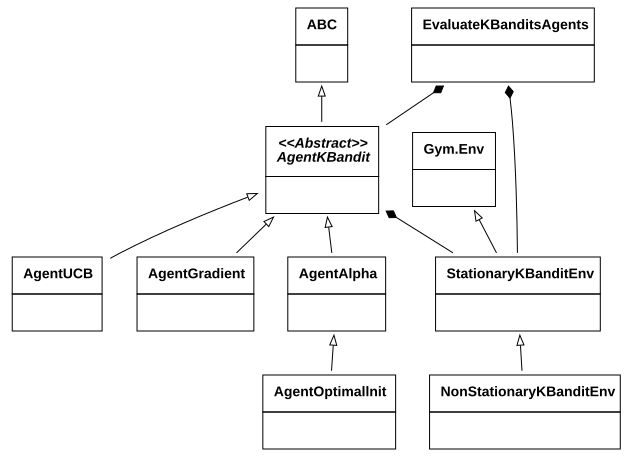

In [ ]:
# Apresenta o projeto das classes de forma gráfica
import graphviz

dot = graphviz.Digraph(comment='K-Bandits Class Diagram')
dot.attr(rankdir='BT')
dot.attr('node', shape='plaintext', fontname='Arial')

# Função auxiliar simplificada: apenas uma divisão
def mklbl(title, abstract=False):
    header = f"<i>&lt;&lt;Abstract&gt;&gt;</i><br/><i>{title}</i>" if abstract else title
    return f'''<<table border="0" cellborder="1" cellspacing="0" cellpadding="10">
                <tr><td><b>{header}</b></td></tr>
                <tr><td port="body" height="30"> </td></tr>
               </table>>'''

# --- DEFINIÇÃO DOS NÓS [cite: 1-12] ---
dot.node('ABC', label=mklbl('ABC'))
dot.node('AgentKBandit', label=mklbl('AgentKBandit', abstract=True))
dot.node('Gym_Env', label=mklbl('Gym.Env'))
dot.node('StationaryKBanditEnv', label=mklbl('StationaryKBanditEnv'))
dot.node('NonStationaryKBanditEnv', label=mklbl('NonStationaryKBanditEnv'))
dot.node('EvaluateKBanditsAgents', label=mklbl('EvaluateKBanditsAgents'))
dot.node('AgentUCB', label=mklbl('AgentUCB'))
dot.node('AgentGradient', label=mklbl('AgentGradient'))
dot.node('AgentAlpha', label=mklbl('AgentAlpha'))
dot.node('AgentOptimallnit', label=mklbl('AgentOptimallnit'))

# --- RELAÇÕES ---
# Heranças (Setas de triângulo vazio)
dot.edge('StationaryKBanditEnv', 'Gym_Env', arrowhead='empty')
dot.edge('NonStationaryKBanditEnv', 'StationaryKBanditEnv', arrowhead='empty')
dot.edge('AgentKBandit', 'ABC', arrowhead='empty')
dot.edge('AgentUCB', 'AgentKBandit', arrowhead='empty')
dot.edge('AgentGradient', 'AgentKBandit', arrowhead='empty')
dot.edge('AgentAlpha', 'AgentKBandit', arrowhead='empty')
dot.edge('AgentOptimallnit', 'AgentAlpha', arrowhead='empty')

# Composições (Losangos)
dot.edge('StationaryKBanditEnv', 'EvaluateKBanditsAgents', arrowhead='diamond')
dot.edge('AgentKBandit', 'EvaluateKBanditsAgents', arrowhead='diamond')
dot.edge("StationaryKBanditEnv", "AgentKBandit", arrowhead='diamond')

dot

# 2.0 - Implementação das Classes

In [2]:
class StationaryKBanditEnv(gym.Env):
    # Entradas:
    # k - número de bandidos,
    # media_q_true - vetor de médias utilizado pela  normal que gera
    # recompensas para cada passo para cada bandido (*)
    # (*) - o bandido que é sorteado com maior media_q_true
    # é considerado escolha ótima para efeito de avaliação dos agentes
    # seed - semente do gerador aleatório
    def __init__(self, k=10, media_q_true = 0, seed=42):
        super().__init__()
        self.k = k
        self.action_space = spaces.Discrete(k)
        self.observation_space = spaces.Discrete(1)
        self.seed = seed
        self.media_q_true = media_q_true # Store media_q_true as an instance variable

        # Initialize true mean action values with mean
        # media_q_true and variance 1
        self.q_true = np.random.normal(self.media_q_true, 1, k)

    # Entradas:
    # action - ação no domínio de self.action_space
    # Saídas:
    # <obs, reward, terminated, trucated, dict info> - padrão de gym.Env
    # reward - recompensa gerada pela ação
    def step(self, action):
        reward = np.random.normal(self.q_true[action], 1)

        return 0, reward, False, False, {"q_true": self.q_true}  # Include q_true in info

    # Entrada:
    # seed - semente
    # Saídas:
    # <obs, dict_info> - padrão de gym.Env
    def reset(self, seed=42):
        super().reset(seed=seed)
        # Reinitialize true mean action values with self.media_q_true and variance 1
        self.q_true = np.random.normal(self.media_q_true, 1, self.k)
        return 0, {}

In [3]:
class NonStationaryKBanditEnv(StationaryKBanditEnv):
  # Entradas:
  # k - número de bandidos,
  # media_q_true - vetor de médias utilizado pela  normal que gera
  # recompensas para cada passo para cada bandido (*)
  # (*) - o bandido que é sorteado com maior media_q_true
  # é considerado escolha ótima para efeito de avaliação dos agentes
  # seed - semente do gerador aleatório
  # sigma_non_stationary - controla o efeito da não estacionariedade
  def __init__(self, k=10, media_q_true=0, seed=42, sigma_non_stationary=0.01):
    super().__init__(k=k, media_q_true=media_q_true, seed=seed)
    self.sigma_non_stationary = sigma_non_stationary

  # Entradas:
  # action - ação no domínio de self.action_space
  # Saídas:
  # <obs, reward, terminated, trucated, dict info> - padrão de gym.Env
  # reward - recompensa gerada pela ação
  def step(self, action):
        # Non-stationary: random walk with std=self.sigma_non_stationary
        self.q_true += np.random.normal(0, self.sigma_non_stationary, self.k)
        reward = np.random.normal(self.q_true[action], 1)

        # return <obs, reward, terminated, trucated, dict info
        return 0, reward, False, False, {"q_true": self.q_true}  # Include q_true in info

In [4]:
# Classe de Agentes Base Abstrata
# Soluções através dec classes derivadas para: ['alpha', 'ucb', 'Optimal_init', 'gradient']
class AgentKBandit(ABC):
  #Entrada:
  # env - ambiente
  def __init__(self, env):
    self.env = env

  def init_run (self, num_steps):
    # self.seed = int(time.time())
    self.seed = 42
    # Initialize Q-values and action counts
    self.Q = np.zeros(self.env.k)
    self.N = np.zeros(self.env.k)
    self.true_q_values = self.env.q_true
    self.optimal_action = np.argmax(self.true_q_values)
    self.run_rewards = np.zeros(num_steps)
    self.run_optimal = np.zeros(num_steps)
    self.run_regrets = np.zeros(num_steps)

  def store_results(self, step, action, reward):
    self.run_rewards[step] = reward
    self.run_optimal[step] = (action == self.optimal_action)
    self.run_regrets[step] = self.calcular_regret(action)

  def calcular_regret(self, acao):
    return max(self.env.q_true) - self.env.q_true[acao]

  @abstractmethod
  def get_label(self):
    pass

  @abstractmethod
  def run(self, num_steps):
    pass




In [5]:
class AgentAlpha(AgentKBandit):

  def __init__(self, env, alpha=0.1, epsilon = 0.1):
    super().__init__(env)
    self.alpha = alpha
    self.epsilon = epsilon

  def get_label(self):
    return f"α = {self.alpha} ε = {self.epsilon}"

  def run(self, num_steps = 1000):
    super().init_run(num_steps)

    for step in range(num_steps):
        # ε-greedy action selection
        if np.random.random() < self.epsilon:
            action = self.env.action_space.sample()
        else:
            # Escolha determinística em caso de empate
            # pega o menor índice entre os empatados
            #action = np.argmax(self.Q)
            # Encontra ações com Q máximo
            max_q = np.max(self.Q)
            best_actions = np.where(self.Q == max_q)[0]
            # Escolha aleatória entre ações ótimas (empates)
            action = np.random.choice(best_actions)  # ← esta é a diferença!

        # Take action and observe reward
        _, reward, _, _, _ = self.env.step(action)

        # Update Q-value
        if self.alpha == 0 or self.alpha == 0.0:  # Sample-average method
            self.N[action] += 1
            self.Q[action] += (reward - self.Q[action]) / self.N[action]
        else:  # Constant step-size
            self.Q[action] += self.alpha * (reward - self.Q[action])

        # Store results
        self.store_results(step, action, reward)

    return self.run_rewards, self.run_optimal, self.run_regrets

In [ ]:
class AgentUCB(AgentKBandit):

  def __init__(self, env, c =0.0):
    super().__init__(env)
    self.c = c

  def get_label(self):
    return f"UCB c = {self.c}"

  def run(self, num_steps = 1000):
    super().init_run(num_steps)

    for step in range(num_steps):

        if step < self.env.k: # Aciona cada um dos K bandidos inicialmente
            action = step
            # Take action and observe reward
            _, reward, _, _, _ = self.env.step(action)
            self.N[action] = 1
            self.Q[action] = reward
        else:
            # 1e-8 - proteção para self.N = 0, o que não ocorre
            action = np.argmax(self.Q + self.c * np.sqrt(np.log(step) / (self.N + 1e-8)))
            # Take action and observe reward
            _, reward, _, _, _ = self.env.step(action)
            self.N[action] += 1
            self.Q[action] += (reward - self.Q[action]) / self.N[action]

        # Store results
        self.store_results(step, action, reward)

    return self.run_rewards, self.run_optimal, self.run_regrets

In [ ]:
class AgentOptimalInit(AgentAlpha):
    def __init__(self, env, alpha=0.1, epsilon=0.1, initial_value=5):
        super().__init__(env, alpha, epsilon)
        self.initial_value = initial_value


    def init_run(self, num_steps):
        # self.seed = int(time.time())
        self.seed = 42
        # Initialize Q-values and action counts
        self.Q = np.full(self.env.k, self.initial_value)
        self.N = np.zeros(self.env.k)
        self.true_q_values = self.env.q_true
        self.optimal_action = np.argmax(self.true_q_values)
        self.run_rewards = np.zeros(num_steps)
        self.run_optimal = np.zeros(num_steps)
        self.run_regrets = np.zeros(num_steps)


    def get_label(self):
        return super().get_label() + f" init = {self.initial_value}"

    def run(self, num_steps=1000):
        self.init_run(num_steps)

        for step in range(num_steps):
            if np.random.random() < self.epsilon:
                action = self.env.action_space.sample()
            else:
                max_q = np.max(self.Q)
                best_actions = np.where(self.Q == max_q)[0]
                action = np.random.choice(best_actions)

            _, reward, _, _, _ = self.env.step(action)

            if self.alpha == 0 or self.alpha == 0.0:
                self.N[action] += 1
                self.Q[action] += (reward - self.Q[action]) / self.N[action]
            else:
                self.Q[action] += self.alpha * (reward - self.Q[action])

            self.store_results(step, action, reward)

        # ← ADICIONE ESTE RETURN:
        return self.run_rewards, self.run_optimal, self.run_regrets

In [ ]:
class AgentGradient(AgentKBandit):
  def __init__(self, env, alpha_lr = 0.1, baseline=True):
    super().__init__(env)
    self.alpha_lr = alpha_lr
    self.baseline = baseline # Corrected: Assign baseline parameter

  def init_run (self, numsteps):
    # self.seed = int(time.time())
    self.seed = 42
    # Initialize H-preferences
    self.H = np.zeros(self.env.k)
    self.R_avg = 0
    self.pi = np.ones(self.env.k)/self.env.k  # Initial policy (uniform)

    self.true_q_values = self.env.q_true
    self.optimal_action = np.argmax(self.true_q_values)
    self.run_rewards = np.zeros(numsteps)
    self.run_optimal = np.zeros(numsteps)
    self.run_regrets = np.zeros(numsteps)

  def get_label(self):
    YN = "" if self.baseline else "No"
    return f"Gradient - lr = {self.alpha_lr}"+ f" - {YN} Baseline "

  def run(self, num_steps):
    self.init_run(num_steps)
    # run_rewards = np.zeros(num_steps)
    # optimal_run_actions = np.zeros(num_steps)

    for step in range(num_steps):
      # Select action according to current policy
      action = np.random.choice(self.env.k, p=self.pi)

      # Take action and observe reward
      _, reward, _, _, _ = self.env.step(action)

      # Store results
      # run_rewards[step] += reward
      # optimal_run_actions[step] += (action == self.optimal_action)
      self.store_results(step, action, reward)

      # Gradient Bandit updates
      if self.baseline:
        self.R_avg = self.R_avg + (reward - self.R_avg)/(step + 1)  # Update average reward
        baseline_val = self.R_avg
      else:
        baseline_val = 0

      # Update all preferences using the correct gradient bandit update rule
      self.H -= self.alpha_lr * (reward - baseline_val) * self.pi
      self.H[action] += self.alpha_lr * (reward - baseline_val)

      # Update policy using softmax
      # Subtract max for numerical stability, then update self.pi
      exp_h = np.exp(self.H - np.max(self.H))
      self.pi = exp_h / exp_h.sum()

    return self.run_rewards, self.run_optimal, self.run_regrets

In [6]:
class EvaluateKBanditAgents():

  def __init__(self, agents, env, num_runs = 100, num_steps = 1000, verbose = True):
    self.agents = agents
    self.env = env
    self.num_runs = num_runs
    self.num_steps = num_steps
    self.verbose = verbose


  def _plot_results_paper(self, avg_rewards, optimal_actions, avg_regrets, cumulative_regrets):
    """Plota 2 figures separadas para o artigo"""

    colors = plt.cm.jet(np.linspace(0, 1, len(self.agents)))
    labels = [agent.get_label() for agent in self.agents]
    steps = np.arange(self.num_steps)

    # FIGURE 1:
    fig1, axes1 = plt.subplots(1, 2, figsize=(12, 5))

    # Average Reward
    for i, (agent, color, label) in enumerate(zip(self.agents, colors, labels)):
        axes1[0].plot(steps, avg_rewards[i], color=color, label=label)
    axes1[0].set_xlabel('Steps')
    axes1[0].set_ylabel('Average Reward')
    axes1[0].set_title('Average Reward vs Steps')
    axes1[0].legend()
    axes1[0].grid(True)

    # % Optimal Action
    for i, (agent, color, label) in enumerate(zip(self.agents, colors, labels)):
        axes1[1].plot(steps, 100.0 * optimal_actions[i], color=color, label=label)
    axes1[1].set_xlabel('Steps')
    axes1[1].set_ylabel('% Optimal Action')
    axes1[1].set_title('Optimal Action Selection vs Steps')
    axes1[1].legend()
    axes1[1].grid(True)

    plt.tight_layout()
    plt.savefig('figure1_barsi_replica.pdf', dpi=300)
    plt.show()

    # FIGURE 2: Análise de Regret (sua contribuição)
    fig2, axes2 = plt.subplots(1, 2, figsize=(12, 5))

    # Average Regret
    for i, (agent, color, label) in enumerate(zip(self.agents, colors, labels)):
        axes2[0].plot(steps, avg_regrets[i], color=color, label=label)
    axes2[0].set_xlabel('Steps')
    axes2[0].set_ylabel('Average Regret')
    axes2[0].set_title('Average Regret vs Steps')
    axes2[0].legend()
    axes2[0].grid(True)

    # Cumulative Regret
    for i, (agent, color, label) in enumerate(zip(self.agents, colors, labels)):
        axes2[1].plot(steps, cumulative_regrets[i], color=color, label=label)
    axes2[1].set_xlabel('Steps')
    axes2[1].set_ylabel('Cumulative Regret')
    axes2[1].set_title('Cumulative Regret vs Steps')
    axes2[1].legend()
    axes2[1].grid(True)

    plt.tight_layout()
    plt.savefig('figure2_regret_analysis.pdf', dpi=300)
    plt.show()

  def run(self):
    num_agents = len(self.agents)
    avg_rewards = np.zeros((num_agents, self.num_steps))
    optimal_actions = np.zeros((num_agents, self.num_steps))
    avg_regrets = np.zeros((num_agents, self.num_steps))
    cumulative_regrets = np.zeros((num_agents, self.num_steps))


    for run in range(self.num_runs):
      if self.verbose:
        print(f"Run {run+1}/{self.num_runs}")

      # Reset environment ONCE per run, before any agent runs
      # This ensures all agents in this 'run' face the same bandit problem instance
      # self.env.reset()

      # em teste
      # Força todos os agentes a usarem o mesmo q_true do dummy_env
      current_q = self.env.q_true.copy()
      for agent in self.agents:
        agent.env.q_true = current_q
        agent.true_q_values = current_q
        agent.optimal_action = np.argmax(current_q)

      for agent_idx, agent in enumerate(self.agents):
        self.env.reset()
        # The agent's *own* state is reset by agent.init_run() within agent.run()
        run_rewards, optimal_run_actions, run_regrets_single_agent = agent.run(self.num_steps)
        avg_rewards[agent_idx, :] += run_rewards / self.num_runs
        optimal_actions[agent_idx, :] += optimal_run_actions / self.num_runs
        avg_regrets[agent_idx, :] += run_regrets_single_agent / self.num_runs

        # Converte para acumulado APENAS para o plot
        steps = np.arange(1, self.num_steps + 1)
        #run_cumulative = run_regrets_single_agent * steps
        run_cumulative = np.cumsum(run_regrets_single_agent)
        cumulative_regrets[agent_idx, :] += run_cumulative / self.num_runs

    self._plot_results_paper(avg_rewards, optimal_actions, avg_regrets, cumulative_regrets)

    return avg_rewards, optimal_actions, avg_regrets, cumulative_regrets

# 3.0 - Casos de Teste do Capítulo 2 do Livro do Sutton & Barto para Ambiente Estacionário

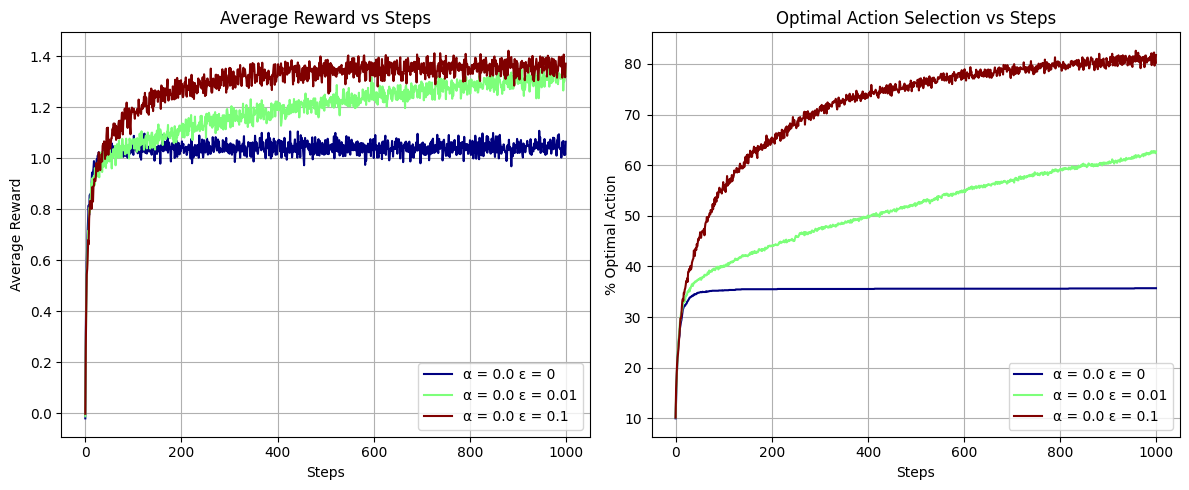

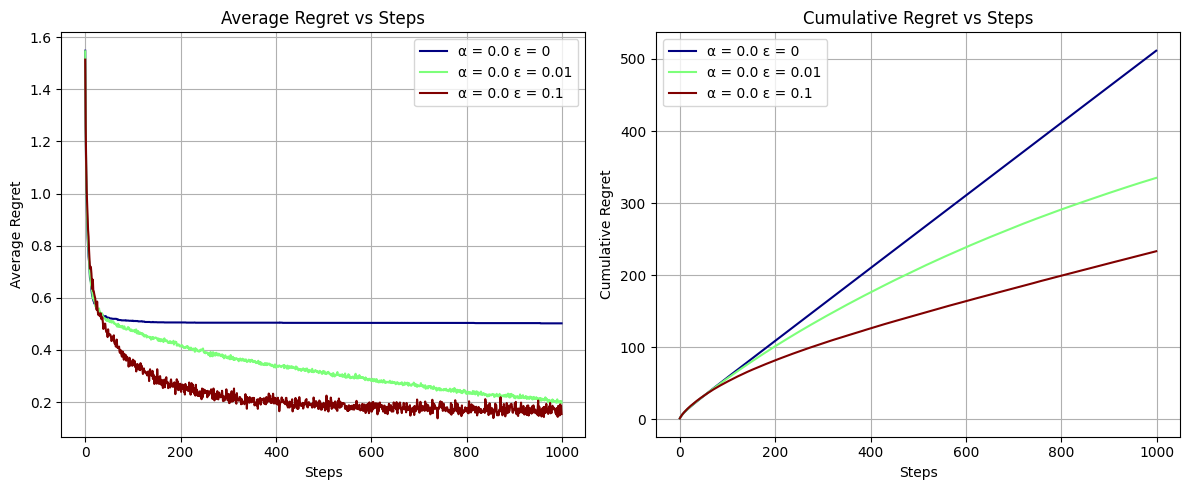

In [ ]:
# Caso de Teste da Figura 2.2 da página 29 do Sutton & Barto
# Objetivo: Comparação  de Greedy Puro (ε = 0) com ε-Greedy (ε! 0)
# Agentes: Agentes Alpha - ε variável
# Ambiente: Estacionário
# Obs: α = 0 utiliza α = 1/n, n - contagem do número de iterações para cálculo da média de valor
env = StationaryKBanditEnv()
alpha = 0.0
epsilon_values = [0, 0.01, 0.1]
num_runs = 2000
num_steps = 1000
agents = [AgentAlpha(env, alpha, epsilon) for epsilon in epsilon_values]
eval = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose = False)
results = eval.run()

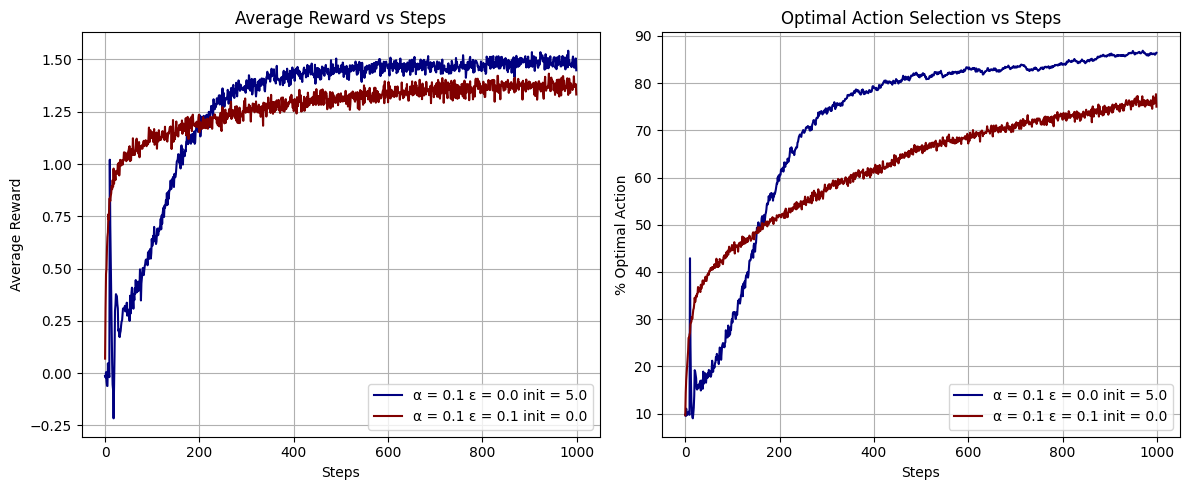

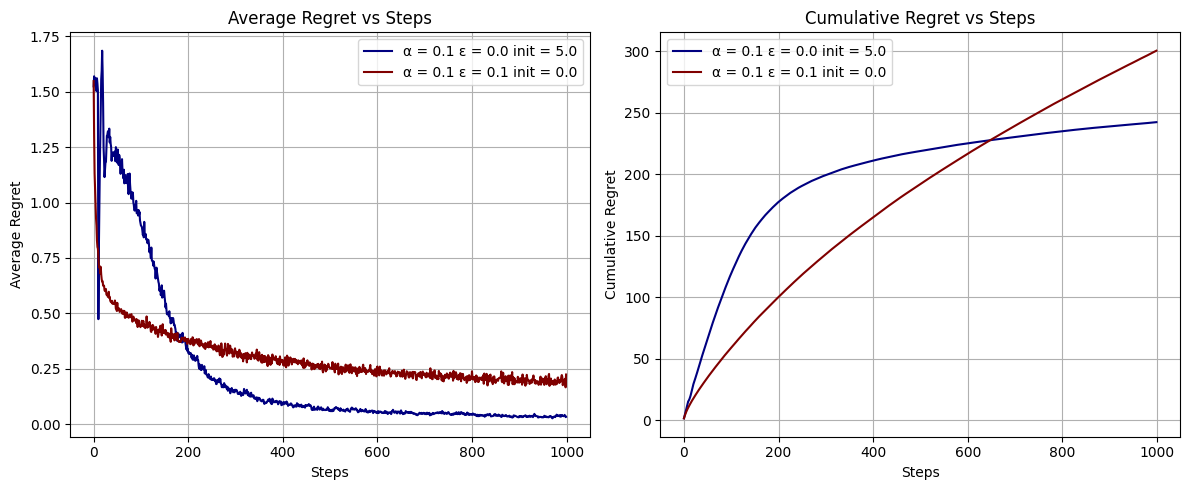

α = 0.1 ε = 0.0 init = 5.0
α = 0.1 ε = 0.1 init = 0.0


In [ ]:
# Caso de Teste da Figura 2.3 da página 34 do Sutton & Barto
# Objetivo: Comparação  de Greedy Puro (ε = 0) e inicializaçao otimista (Q0 = 5)
# com ε-Greedy (ε = 0.1) e inicialização zerada (Q0 = 0)
# Agentes: Agentes Alpha e Optimal Init - ε-Greedy (ε = 0.1)
# Ambiente: Estacionário
# Obs: α = 0.1 constante
env = StationaryKBanditEnv()
alpha = 0.1 # Using constant step-size
epsilon_values = [0.0, 0.1]
initial_values = [5.0, 0.0] # Correspondem aos epsilon_values
num_runs = 2000
num_steps = 1000

agents_optimistic_alpha = []
for epsilon, initial_value in zip(epsilon_values, initial_values):
  agents_optimistic_alpha.append(AgentOptimalInit(env, alpha, epsilon, initial_value))

eval_optimistic_alpha = EvaluateKBanditAgents(agents_optimistic_alpha, env, num_runs, num_steps, verbose = False)
results_optimistic_alpha = eval_optimistic_alpha.run()

for agent in agents_optimistic_alpha:
  print(agent.get_label())

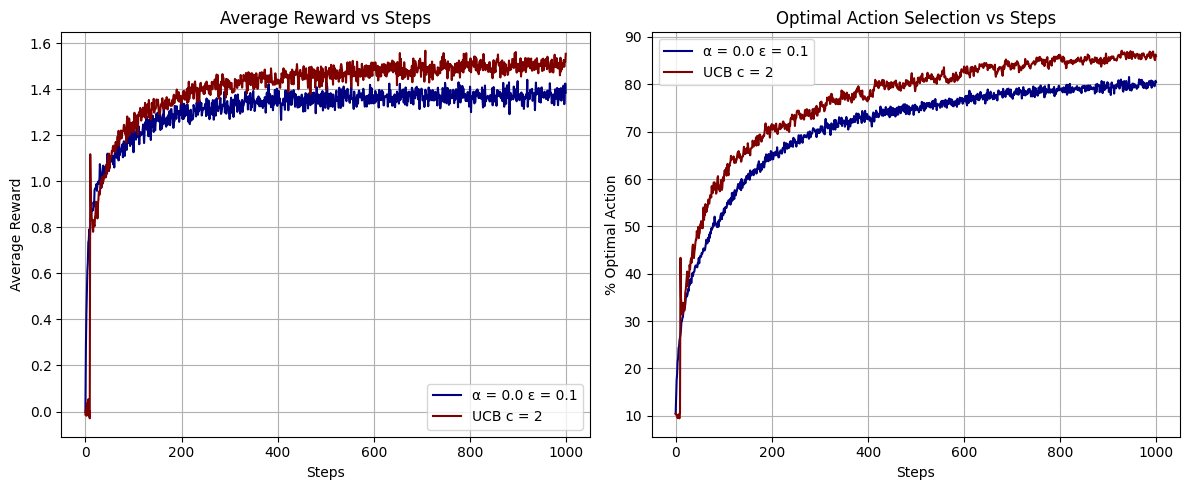

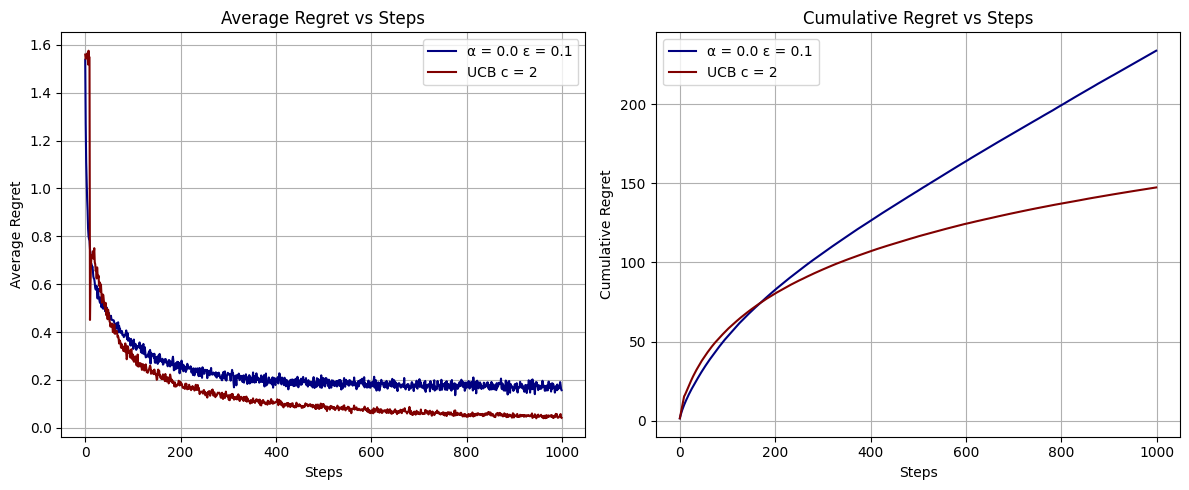

In [ ]:
# Caso de Teste da Figura 2.4 da página 36 do Sutton & Barto
# Objetivo: Comparação  de Agente Alpha - ε-Greedy (ε =  0,1) versus Agente UCB (c = 2)
# Agentes: Agentes Alpha ε-Greedy (ε = 0.1) e UCB (c = 2)
# Ambiente: Estacionário
env = StationaryKBanditEnv()
alpha = 0.0
epsilon = 0.1
c = 2
num_runs = 2000
num_steps = 1000
agents = [AgentAlpha(env, alpha, epsilon), AgentUCB(env, c)]
eval = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose = False)
results = eval.run()

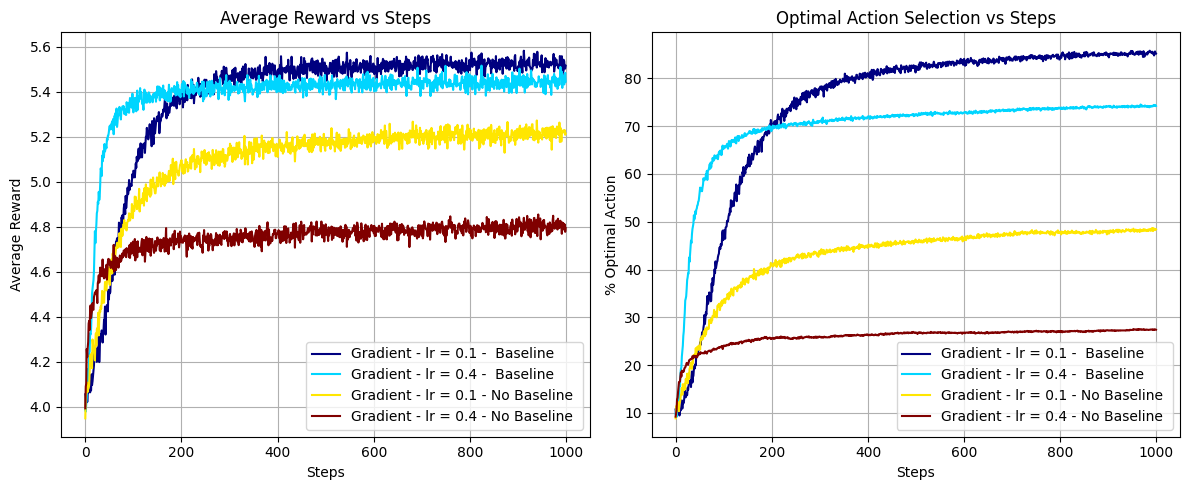

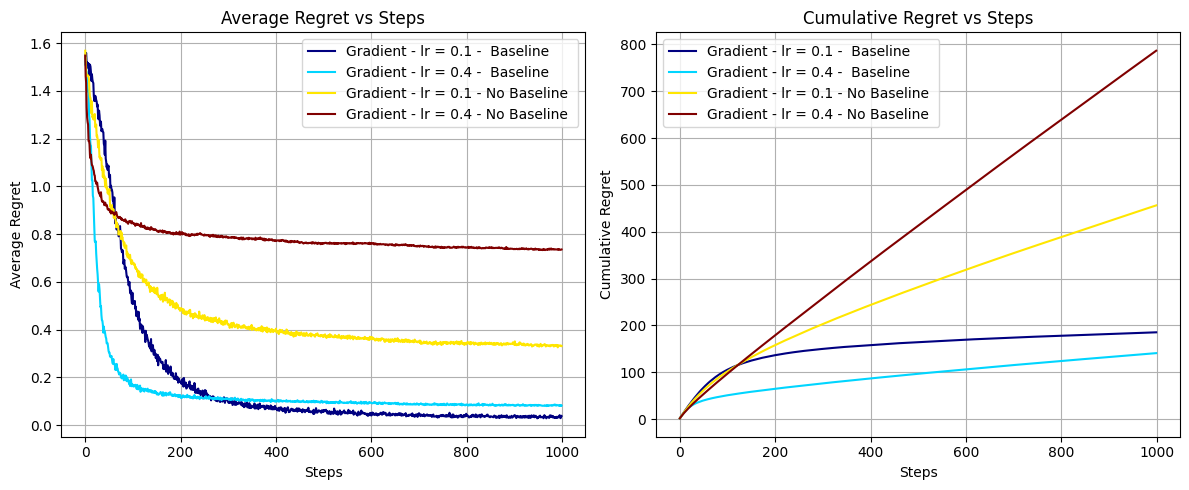

In [ ]:
# Caso de Teste da Figura 2.5 da página 38 do Sutton & Barto
# Objetivo: Comparação  de Agentes Gradiente learning rate - lr (lr = 0.1 e lr = 0.4), com ou sem baseline
# Agentes: Agentes Gradiente
# Ambiente: Estacionário
media = 4
num_runs = 2000
num_steps = 1000

# Cria um único ambiente que será usado como referência para gerar os q_true
# v = StationaryKBanditEnv(media_q_true=media)
env = StationaryKBanditEnv(media_q_true=media)

alpha_lr_values = [0.1, 0.4, 0.1, 0.4]
baseline_values = [True, True, False, False]

agents_gradient = []
for alpha_lr, baseline in zip(alpha_lr_values, baseline_values):
    # Cada agente tem seu PRÓPRIO ambiente (cópia independente)
    # env = StationaryKBanditEnv(media_q_true=media)
    agents_gradient.append(AgentGradient(env, alpha_lr, baseline))

# O evaluator recebe o ambiente de referência (v) para controlar as seeds
eval_gradient = EvaluateKBanditAgents(agents_gradient, env, num_runs, num_steps, verbose=False)
results = eval_gradient.run()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Comparação de Algoritmos para Solução dos K-Banditos em um range de hiperparâmetros
def ComparativeRangeEvaluation(stationary_env = True, num_runs = 2000, num_steps = 1000, Param_exp_range = (-7, 3), epsilon_range = (0, 6) , ucb_range = (3, 10), optimin_range = (5, 10),gradient_range = (2, 9)):
  # ============================================
  # CONFIGURAÇÕES GERAIS
  # ============================================
  media = 0

  if stationary_env:
    env = StationaryKBanditEnv(media_q_true=media)
  else:
    env = NonStationaryKBanditEnv(sigma_non_stationary=0.1)

  # Definição dos parâmetros (como no código oficial)
  Param = [2**i for i in range (Param_exp_range[0], Param_exp_range[1])]

  # Intervalos para cada algoritmo (como no livro)
  epsilon_Param = Param[epsilon_range[0]:epsilon_range[1]]  # [1/128, 1/64, 1/32, 1/16, 1/8, 1/4]
  ucb_Param = Param[ucb_range[0]:ucb_range[1]]  # [1/16, 1/8, 1/4, 1/2, 1, 2, 4]
  optimin_Param = Param[optimin_range[0]:optimin_range[1]]  # [0.25, 0.5, 1, 2, 4]
  gradient_Param = Param[gradient_range[0]:gradient_range[1]]  # [1/32, 1/16, 1/8, 1/4, 1/2, 1, 2]

  print("=" * 50)
  print("PARÂMETROS UTILIZADOS")
  print("=" * 50)
  print(f"ε-greedy:     {[f'{p:.4f}' for p in epsilon_Param]}")
  print(f"UCB:          {[f'{p:.4f}' for p in ucb_Param]}")
  print(f"Optimistic:   {optimin_Param}")
  print(f"Gradient:     {[f'{p:.4f}' for p in gradient_Param]}")

  # ============================================
  # 1. EPSILON-GREEDY
  # ============================================
  print("\nRodando ε-greedy...")
  #env = StationaryKBanditEnv()
  if stationary_env:
    agents = [AgentAlpha(env, alpha=0.0, epsilon=eps) for eps in epsilon_Param]
  else:
    agents = [AgentAlpha(env, alpha=0.1, epsilon=eps) for eps in epsilon_Param]

  eval = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose=True)
  avg_rewards_eps, optimal_actions_eps, _, _ = eval.run()
  mean_eps = np.mean(avg_rewards_eps, axis=1)
  mean_oa_eps = 100.0*np.mean(optimal_actions_eps, axis=1)

  # ============================================
  # 2. UCB
  # ============================================
  print("Rodando UCB...")
  #env = StationaryKBanditEnv()
  env.reset()
  agents = [AgentUCB(env, c=c) for c in ucb_Param]
  eval = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose=True)
  avg_rewards_ucb, optimal_actions_ucb, _, _ = eval.run()
  mean_ucb = np.mean(avg_rewards_ucb, axis=1)
  mean_oa_ucb = 100.0*np.mean(optimal_actions_ucb, axis=1)

  # ============================================
  # 3. OPTIMISTIC INITIALIZATION
  # ============================================
  print("Rodando Optimistic Initialization...")

  # env = StationaryKBanditEnv()
  env.reset()
  alpha = 0.1      # passo constante (como no livro)
  epsilon = 0.0    # greedy puro (como no livro)
  initial_values = [0.25, 0.5, 1.0, 2.0, 4.0]  # 2^-2 a 2^2

  agents_optimistic = []
  for init_val in initial_values:
      agents_optimistic.append(AgentOptimalInit(env, alpha, epsilon, init_val))

  eval_optimistic = EvaluateKBanditAgents(agents_optimistic, env, num_runs, num_steps, verbose=True)
  avg_rewards_opt, optimal_actions_opt, _, _ = eval_optimistic.run()
  mean_opt = np.mean(avg_rewards_opt, axis=1)
  mean_oa_opt = 100.0*np.mean(optimal_actions_opt, axis=1)

  print(f"optimistic_Param: {initial_values}")
  print(f"optimistic_rewards: {mean_opt}")

  # ============================================
  # 4. GRADIENT BANDIT
  # ============================================
  print("Rodando Gradient Bandit...")
  # v = StationaryKBanditEnv(media_q_true=media)
  # env_grad = StationaryKBanditEnv(media_q_true=media)
  env.reset()

  # Cria um único ambiente que será usado como referência para gerar os q_true

  agents_gradient = []
  for alpha_lr in gradient_Param:
      # env_grad = StationaryKBanditEnv(media_q_true=media)
      agents_gradient.append(AgentGradient(env, alpha_lr, baseline=True))

  eval_gradient = EvaluateKBanditAgents(agents_gradient, env, num_runs, num_steps, verbose=True)
  avg_rewards_grad, optimal_actions_grad, _, _ = eval_gradient.run()
  mean_grad = np.mean(avg_rewards_grad, axis=1)
  mean_oa_grad = 100.0*np.mean(optimal_actions_grad, axis=1)

  # ============================================
  # PLOT DAS 4 CURVAS JUNTAS (Figura 2.6)
  # ============================================
  def format_as_power(x):
      exponent = int(np.log2(x))
      return f'$2^{{{exponent}}}$'

  plt.figure(figsize=(10, 6))

  # Curva 1: ε-greedy
  plt.semilogx(epsilon_Param, mean_eps, 'o-', linewidth=2, markersize=6,
              label='ε-greedy', color='blue')

  # Curva 2: UCB
  plt.semilogx(ucb_Param, mean_ucb, 's-', linewidth=2, markersize=6,
              label='UCB', color='red')

  # Curva 3: Gradient Bandit
  plt.semilogx(gradient_Param, mean_grad, '^-', linewidth=2, markersize=6,
              label='gradient bandit', color='green')

  # Curva 4: Optimistic Initialization
  plt.semilogx(optimin_Param, mean_opt, 'd-', linewidth=2, markersize=6,
              label='optimistic initialization', color='purple')

  # Configurações do gráfico
  plt.gca().set_xscale('log')
  plt.xlabel('Parameter ($2^x$)', fontsize=12)
  plt.ylabel('Average reward', fontsize=12)
  plt.title('Ambiente Nào Estacionário', fontsize=14)
  plt.legend(loc='best', fontsize=10)
  plt.grid(True, alpha=0.3)
  if stationary_env:
      plt.ylim(1.0, 1.5)  # Escala como no livro para ambiente estacionário


  # Configurar ticks do eixo X (unificar os parâmetros)
  all_params = sorted(set(epsilon_Param + ucb_Param + gradient_Param + optimin_Param))
  xtick_labels = [format_as_power(p) for p in all_params]
  plt.xticks(all_params, xtick_labels, rotation=45)

  plt.tight_layout()
  plt.show()

  # ============================================
  # PLOT DAS 4 CURVAS JUNTAS (% OPTIMAL)
  # ============================================

  plt.figure(figsize=(10, 6))

  # Curva 1: ε-greedy
  plt.semilogx(epsilon_Param, mean_oa_eps, 'o-', linewidth=2, markersize=6,
              label='ε-greedy', color='blue')

  # Curva 2: UCB
  plt.semilogx(ucb_Param, mean_oa_ucb, 's-', linewidth=2, markersize=6,
              label='UCB', color='red')

  # Curva 3: Gradient Bandit
  plt.semilogx(gradient_Param, mean_oa_grad, '^-', linewidth=2, markersize=6,
              label='gradient bandit', color='green')

  # Curva 4: Optimistic Initialization
  plt.semilogx(optimin_Param, mean_oa_opt, 'd-', linewidth=2, markersize=6,
              label='optimistic initialization', color='purple')

  # Configurações do gráfico
  plt.gca().set_xscale('log')
  plt.xlabel('Parameter ($2^x$)', fontsize=12)
  plt.ylabel('% Optimal Action', fontsize=12)
  plt.title('Ambiente Nào Estacionário', fontsize=14)
  plt.legend(loc='best', fontsize=10)
  plt.grid(True, alpha=0.3)
  plt.ylim(0.0, 100.0)  #


  # Configurar ticks do eixo X (unificar os parâmetros)
  all_params = sorted(set(epsilon_Param + ucb_Param + gradient_Param + optimin_Param))
  xtick_labels = [format_as_power(p) for p in all_params]
  plt.xticks(all_params, xtick_labels, rotation=45)

  plt.tight_layout()
  plt.show()

  return mean_eps, mean_ucb, mean_opt, mean_grad, epsilon_Param, ucb_Param, optimin_Param, gradient_Param






PARÂMETROS UTILIZADOS
ε-greedy:     ['0.0078', '0.0156', '0.0312', '0.0625', '0.1250', '0.2500']
UCB:          ['0.0625', '0.1250', '0.2500', '0.5000', '1.0000', '2.0000', '4.0000']
Optimistic:   [0.25, 0.5, 1, 2, 4]
Gradient:     ['0.0312', '0.0625', '0.1250', '0.2500', '0.5000', '1.0000', '2.0000']

Rodando ε-greedy...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Ru

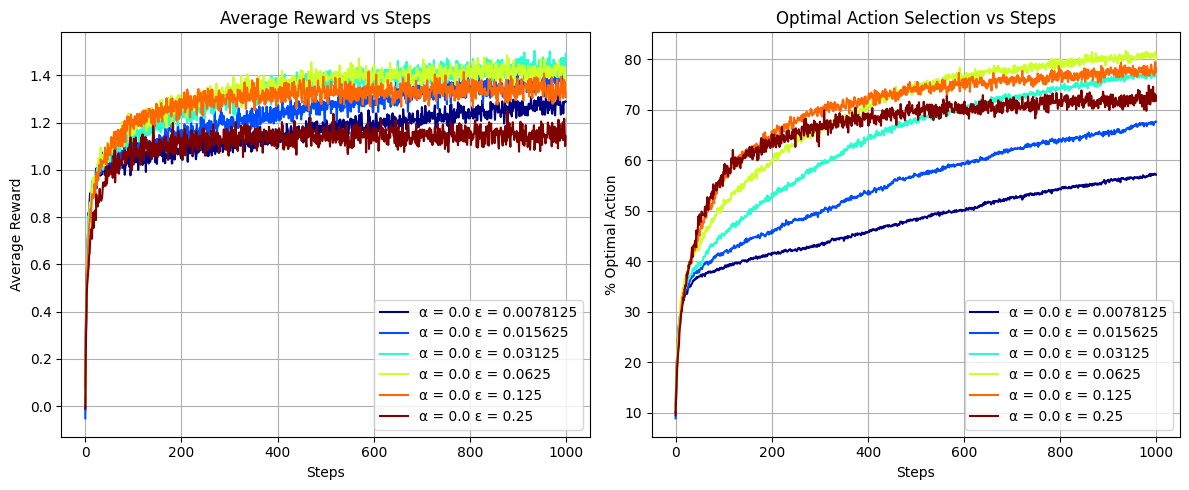

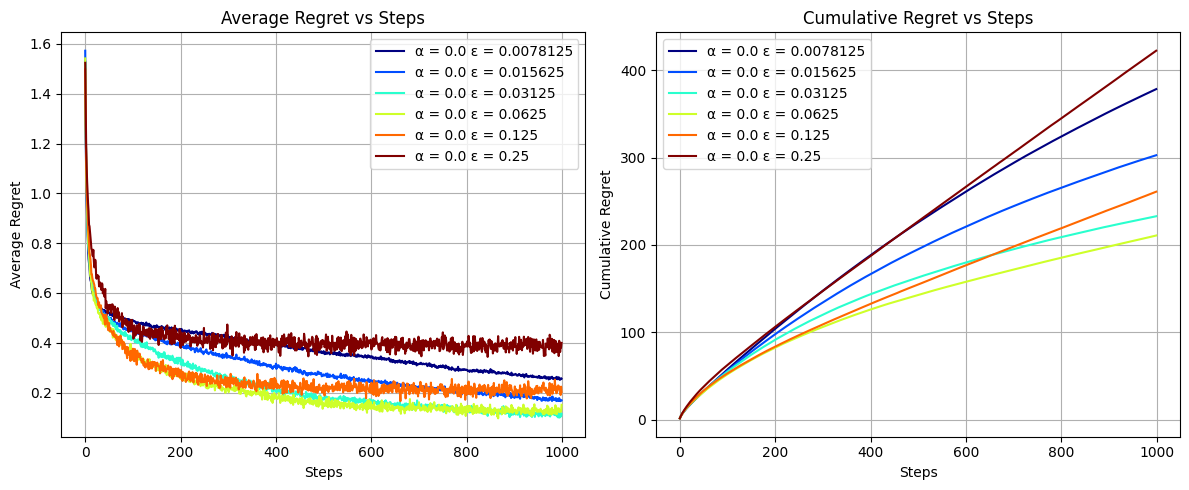

Rodando UCB...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Run 58/2000
Run 59/2000
Run 60/2000
Run 61/2000
Run 62/2000
Run 63/2000
Run 64/2000
Run 65/2000
Run 66/2000
Run 67/2000
Run 68/2000
Run 69/2000
Run 70/2000
Run 71/2000
Run 72/2000
Run 73/2000
Run 74/2000
Run 75/2000
Run 76/2000
Run 77/2000
Run 78/2000
Run 79/2000
Run 80/2000
Run 81/2000
Run 82/2000
Run 83/200

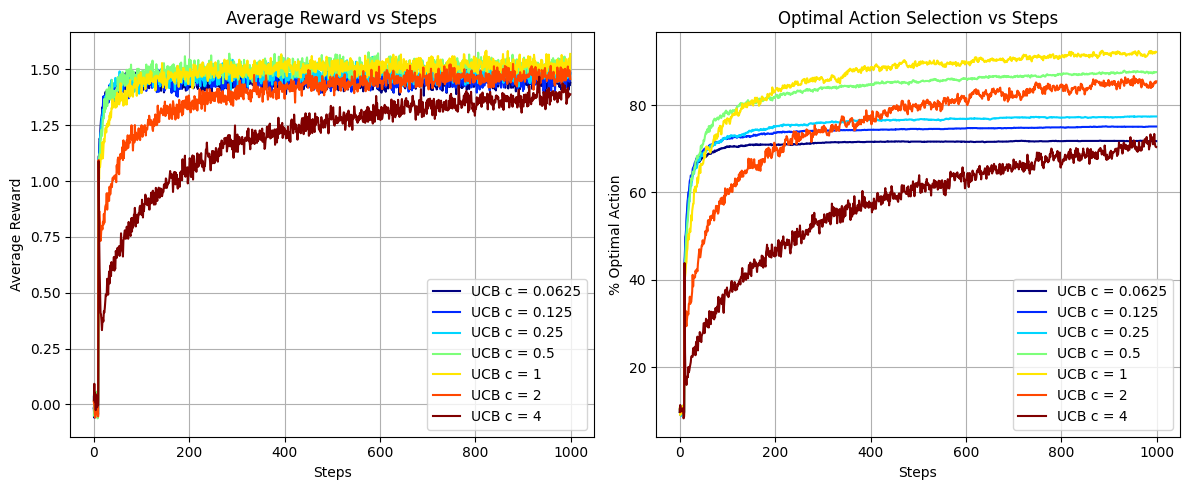

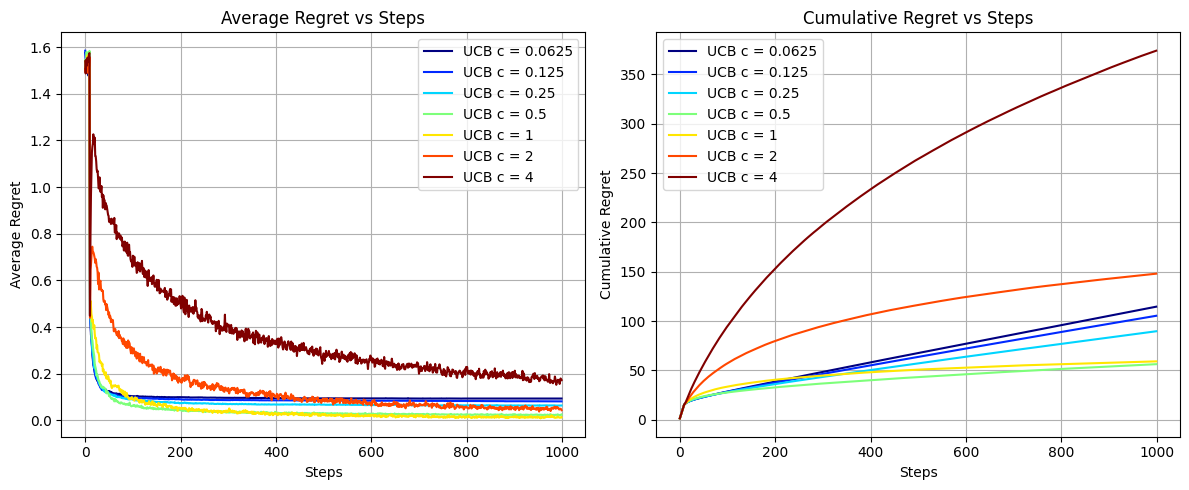

Rodando Optimistic Initialization...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Run 58/2000
Run 59/2000
Run 60/2000
Run 61/2000
Run 62/2000
Run 63/2000
Run 64/2000
Run 65/2000
Run 66/2000
Run 67/2000
Run 68/2000
Run 69/2000
Run 70/2000
Run 71/2000
Run 72/2000
Run 73/2000
Run 74/2000
Run 75/2000
Run 76/2000
Run 77/2000
Run 78/2000
Run 79/2000
Run 80/2000
Run 81/2000


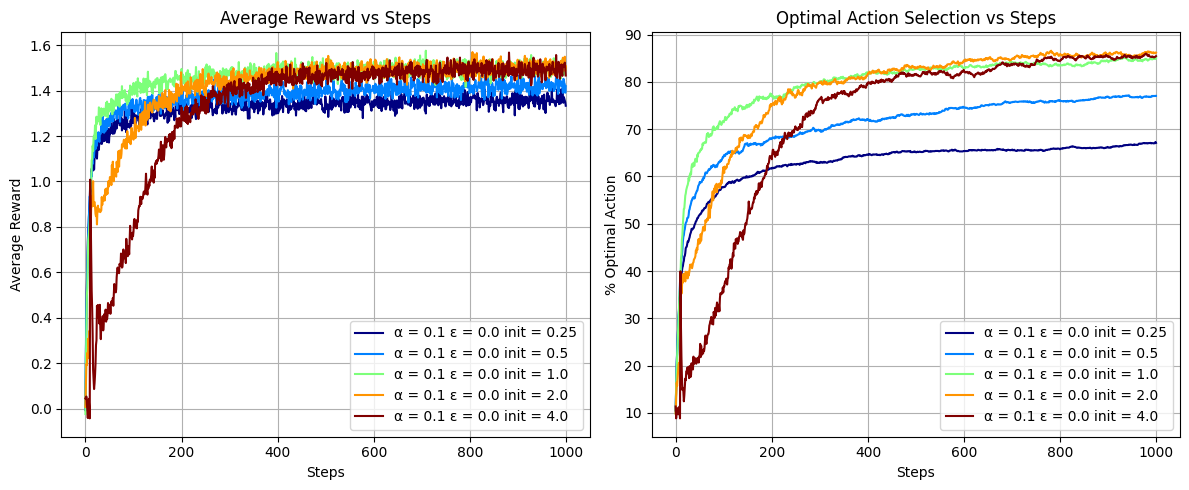

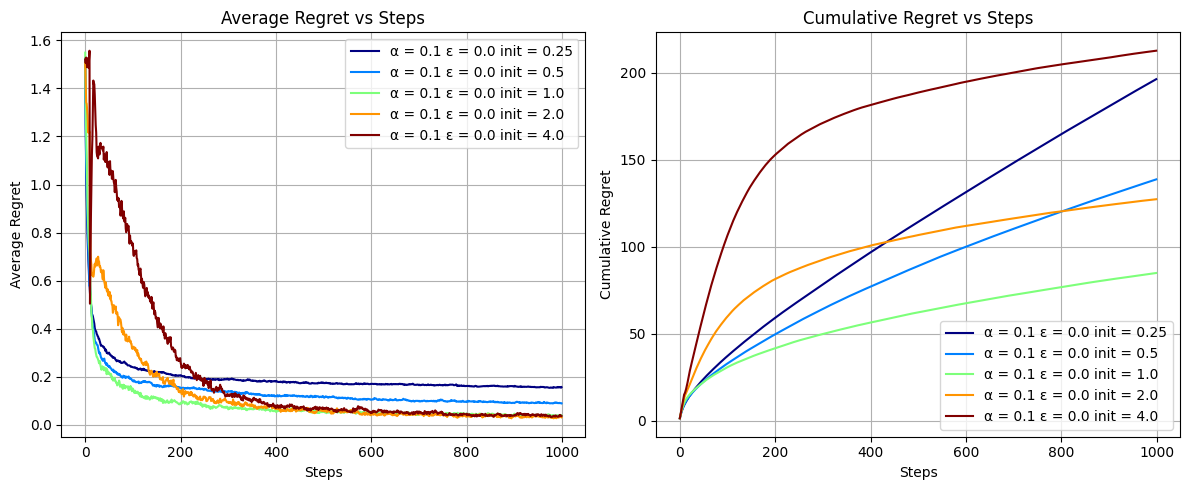

optimistic_Param: [0.25, 0.5, 1.0, 2.0, 4.0]
optimistic_rewards: [1.32043259 1.37429341 1.45770399 1.41319651 1.31837726]
Rodando Gradient Bandit...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Run 58/2000
Run 59/2000
Run 60/2000
Run 61/2000
Run 62/2000
Run 63/2000
Run 64/2000
Run 65/2000
Run 66/2000
Run 67/2000
Run 68/2000
Run 69/2000
Run 70/2000
Run 71/2000
Run 72/2

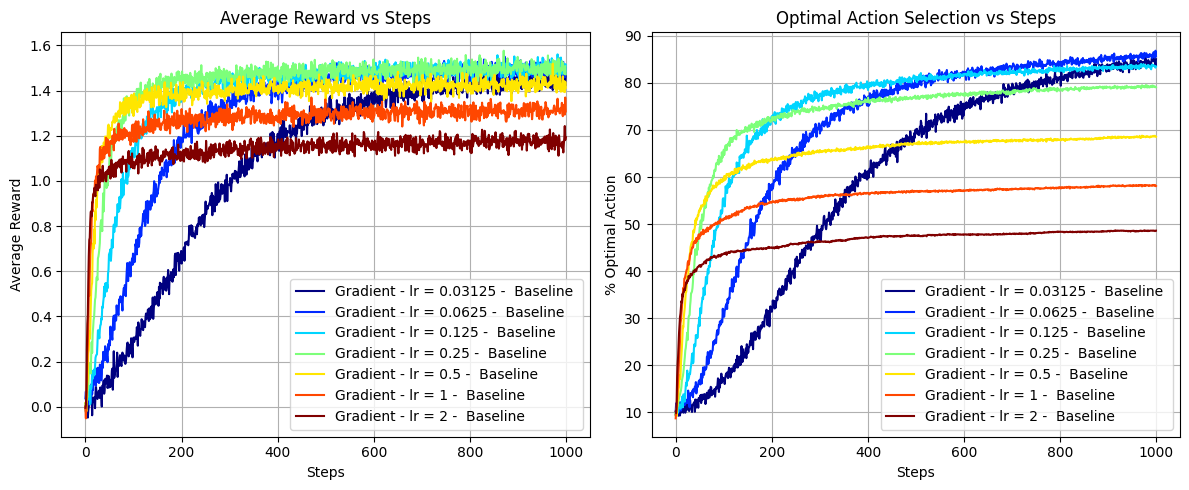

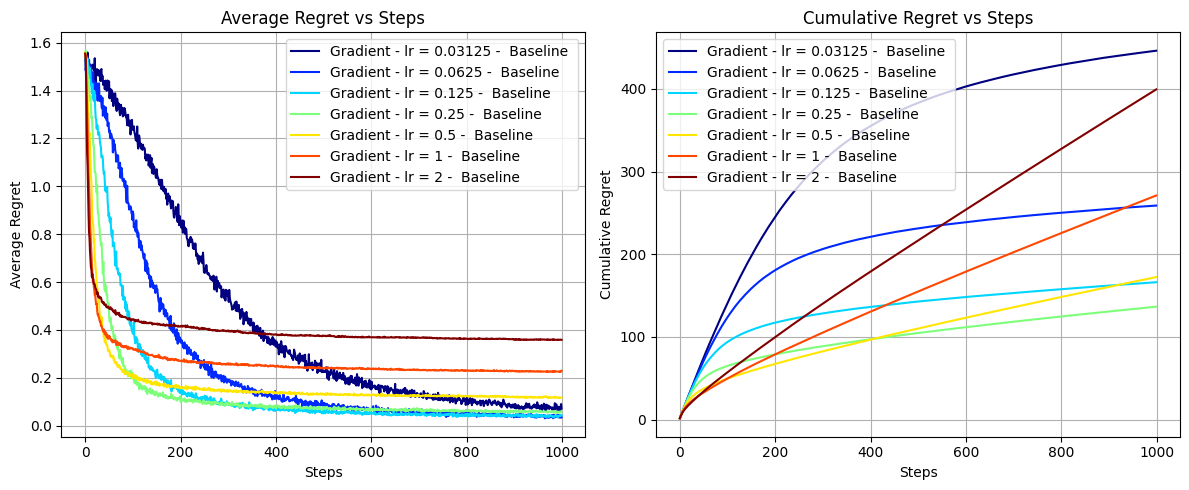

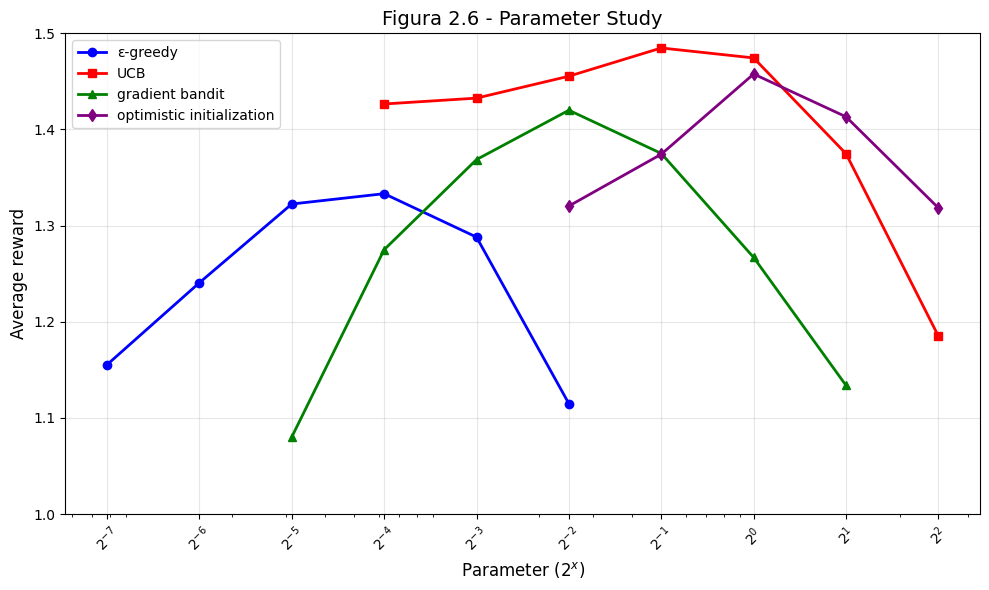

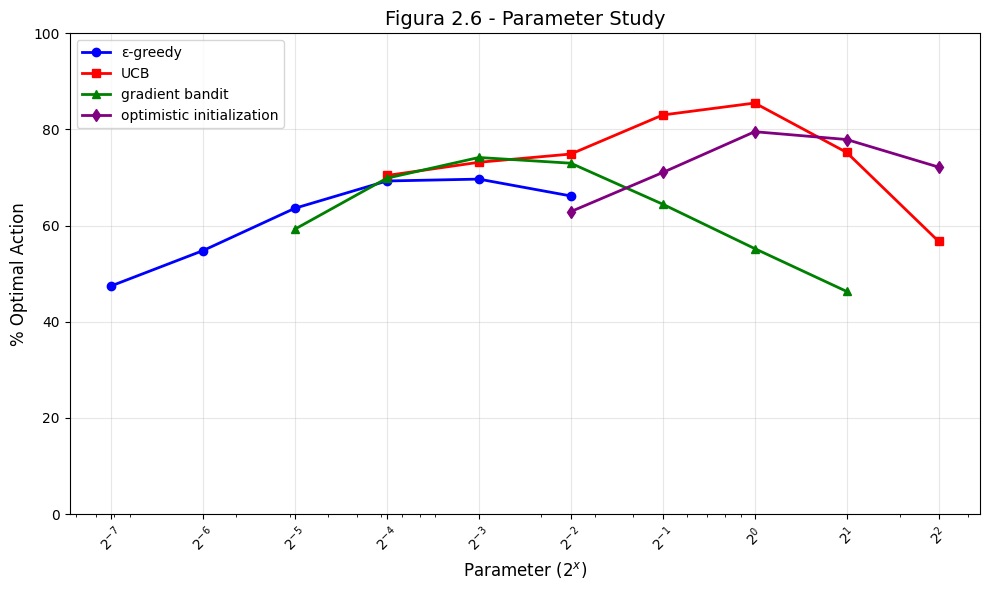

In [ ]:
# Caso de Teste - Figura 2.6 pg 42 do Sutton & Barto - Comparação dos algoritmos para o Caso Estacionário
mean_eps, mean_ucb, mean_opt, mean_grad, epsilon_Param, ucb_Param, optimin_Param, gradient_Param = ComparativeRangeEvaluation()


In [ ]:
# ============================================
# PRINT DOS VALORES NUMÉRICOS
# ============================================
print("\n" + "=" * 60)
print("RESULTADOS NUMÉRICOS (Média sobre tempo)")
print("=" * 60)

print("\nε-greedy:")
for p, r in zip(epsilon_Param, mean_eps):
    print(f"  {p:6.4f} (2^{int(np.log2(p)):2d}): {r:.4f}")

print("\nUCB:")
for p, r in zip(ucb_Param, mean_ucb):
    print(f"  {p:6.4f} (2^{int(np.log2(p)):2d}): {r:.4f}")

print("\nGradient Bandit:")
for p, r in zip(gradient_Param, mean_grad):
    print(f"  {p:6.4f} (2^{int(np.log2(p)):2d}): {r:.4f}")

print("\nOptimistic Initialization:")
for p, r in zip(optimin_Param, mean_opt):
    print(f"  {p:6.4f} (2^{int(np.log2(p)):2d}): {r:.4f}")


RESULTADOS NUMÉRICOS (Média sobre tempo)

ε-greedy:
  0.0078 (2^-7): 1.1553
  0.0156 (2^-6): 1.2406
  0.0312 (2^-5): 1.3225
  0.0625 (2^-4): 1.3333
  0.1250 (2^-3): 1.2881
  0.2500 (2^-2): 1.1149

UCB:
  0.0625 (2^-4): 1.4265
  0.1250 (2^-3): 1.4326
  0.2500 (2^-2): 1.4554
  0.5000 (2^-1): 1.4848
  1.0000 (2^ 0): 1.4744
  2.0000 (2^ 1): 1.3748
  4.0000 (2^ 2): 1.1851

Gradient Bandit:
  0.0312 (2^-5): 1.0801
  0.0625 (2^-4): 1.2750
  0.1250 (2^-3): 1.3687
  0.2500 (2^-2): 1.4200
  0.5000 (2^-1): 1.3751
  1.0000 (2^ 0): 1.2669
  2.0000 (2^ 1): 1.1338

Optimistic Initialization:
  0.2500 (2^-2): 1.3204
  0.5000 (2^-1): 1.3743
  1.0000 (2^ 0): 1.4577
  2.0000 (2^ 1): 1.4132
  4.0000 (2^ 2): 1.3184


# 4.0 - Variações dos Casos de Teste do Barto para Ambiente Estacionário

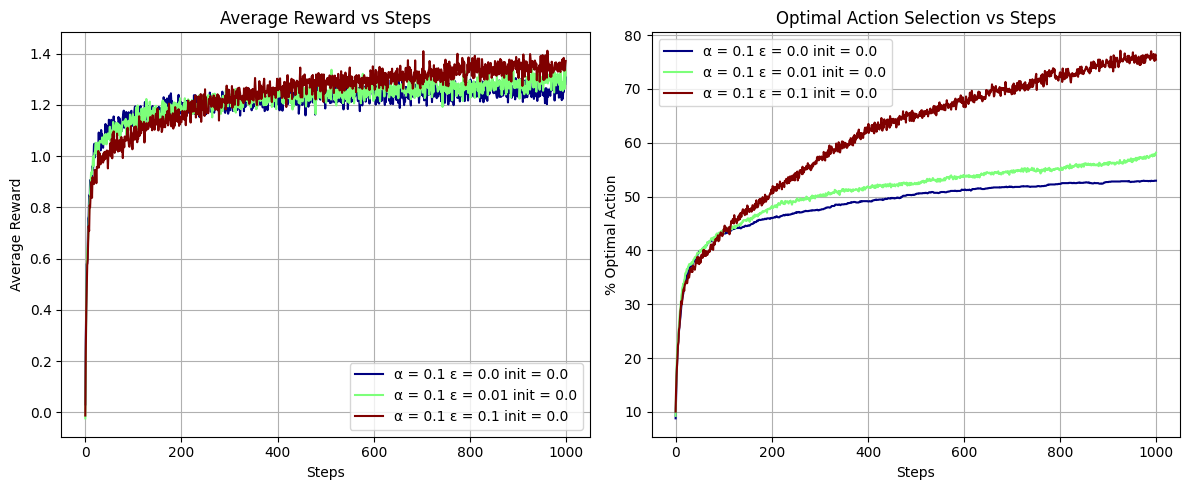

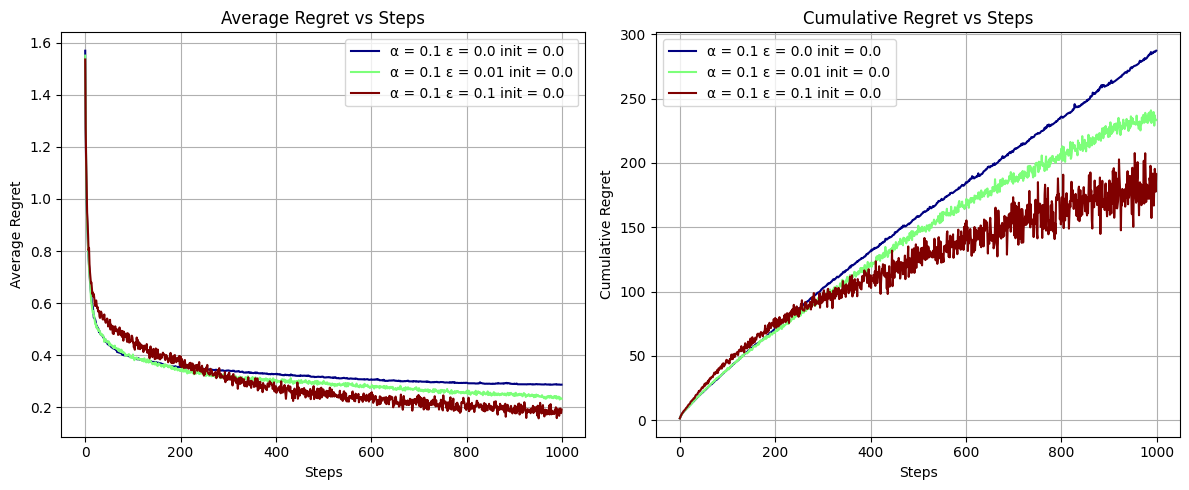

α = 0.1 ε = 0.0 init = 0.0
α = 0.1 ε = 0.01 init = 0.0
α = 0.1 ε = 0.1 init = 0.0


In [ ]:
# Variação do Caso de Teste da Figura 2.3 da página 34 do Sutton & Barto
alpha = 0.1 # Using constant step-size
epsilon_values = [0.0, 0.01, 0.1]
initial_values = [0.0, 0.0, 0.0] # Correspondem aos epsilon_values
num_runs = 2000
num_steps = 1000

agents_optimistic_alpha = []
for epsilon, initial_value in zip(epsilon_values, initial_values):
  agents_optimistic_alpha.append(AgentOptimalInit(env, alpha, epsilon, initial_value))

eval_optimistic_alpha = EvaluateKBanditAgents(agents_optimistic_alpha, env, num_runs, num_steps, verbose = False)
results_optimistic_alpha = eval_optimistic_alpha.run()

for agent in agents_optimistic_alpha:
  print(agent.get_label())

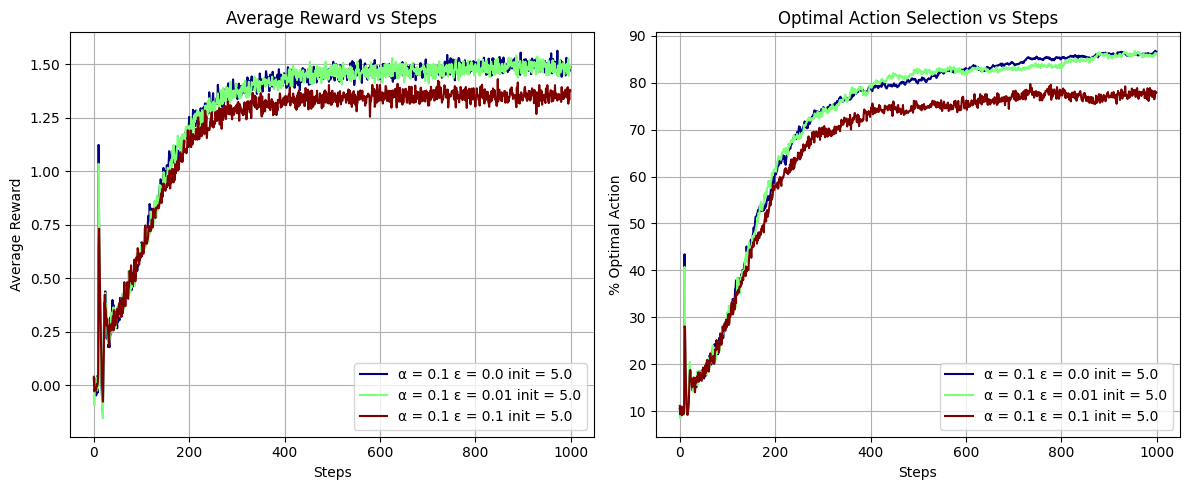

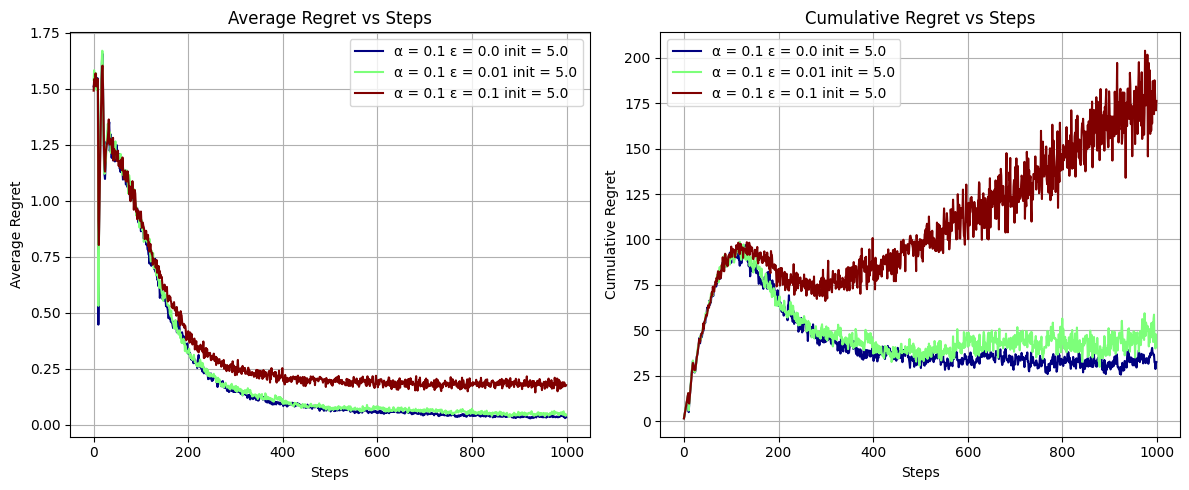

α = 0.1 ε = 0.0 init = 5.0
α = 0.1 ε = 0.01 init = 5.0
α = 0.1 ε = 0.1 init = 5.0


In [ ]:
# Variação do Caso de Teste da Figura 2.3 da página 34 do Sutton & Barto
alpha = 0.1 # Using constant step-size
epsilon_values = [0.0, 0.01, 0.1]
initial_values = [5.0, 5.0, 5.0] # Correspondem aos epsilon_values
num_runs = 2000
num_steps = 1000

agents_optimistic_alpha = []
for epsilon, initial_value in zip(epsilon_values, initial_values):
  agents_optimistic_alpha.append(AgentOptimalInit(env, alpha, epsilon, initial_value))

eval_optimistic_alpha = EvaluateKBanditAgents(agents_optimistic_alpha, env, num_runs, num_steps, verbose = False)
results_optimistic_alpha = eval_optimistic_alpha.run()

for agent in agents_optimistic_alpha:
  print(agent.get_label())

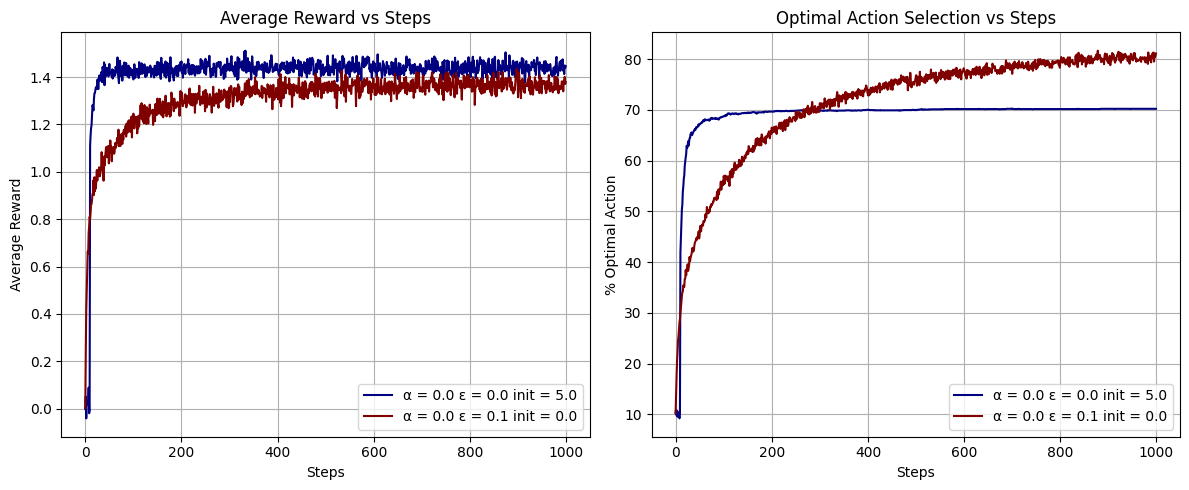

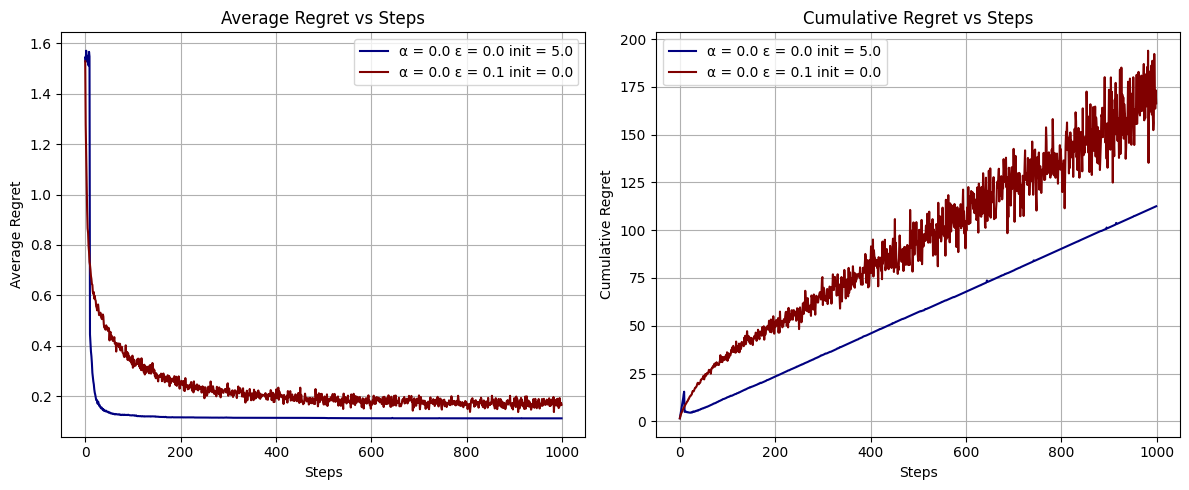

α = 0.0 ε = 0.0 init = 5.0
α = 0.0 ε = 0.1 init = 0.0


In [ ]:
# Variação Caso de Teste da Figura 2.3 da página 34 do Sutton & Barto
alpha = 0.0 # Using constant step-size
epsilon_values = [0.0, 0.1]
initial_values = [5.0, 0.0] # Correspondem aos epsilon_values
num_runs = 2000
num_steps = 1000

agents_optimistic_alpha = []
for epsilon, initial_value in zip(epsilon_values, initial_values):
  agents_optimistic_alpha.append(AgentOptimalInit(env, alpha, epsilon, initial_value))

eval_optimistic_alpha = EvaluateKBanditAgents(agents_optimistic_alpha, env, num_runs, num_steps, verbose = False)
results_optimistic_alpha = eval_optimistic_alpha.run()

for agent in agents_optimistic_alpha:
  print(agent.get_label())

# 5.0 - *Casos* de Teste para Ambiente Não Estacionário

PARÂMETROS UTILIZADOS
ε-greedy:     ['0.0078', '0.0156', '0.0312', '0.0625', '0.1250', '0.2500']
UCB:          ['0.0625', '0.1250', '0.2500', '0.5000', '1.0000', '2.0000', '4.0000']
Optimistic:   [0.25, 0.5, 1, 2, 4]
Gradient:     ['0.0312', '0.0625', '0.1250', '0.2500', '0.5000', '1.0000', '2.0000']

Rodando ε-greedy...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Ru

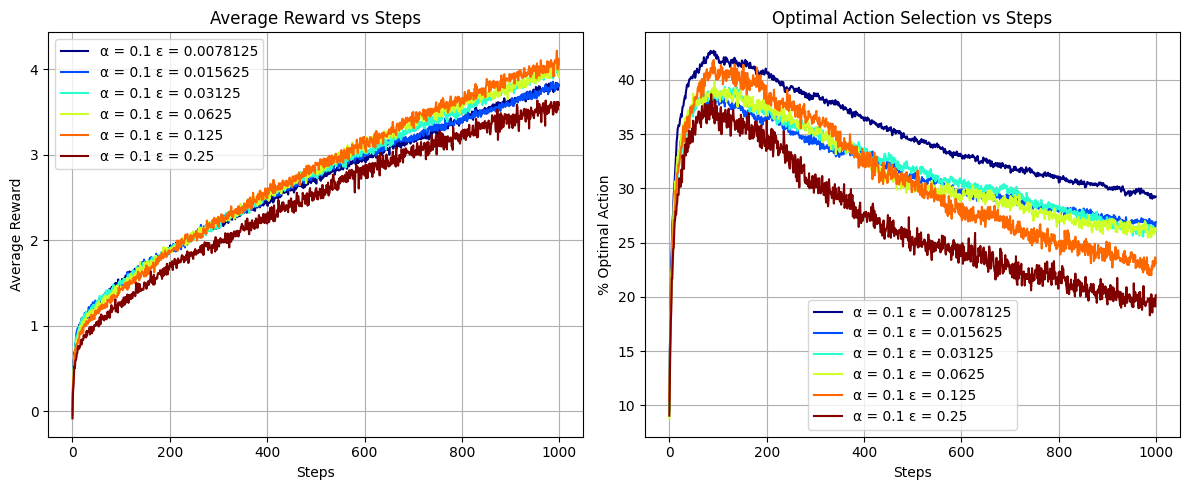

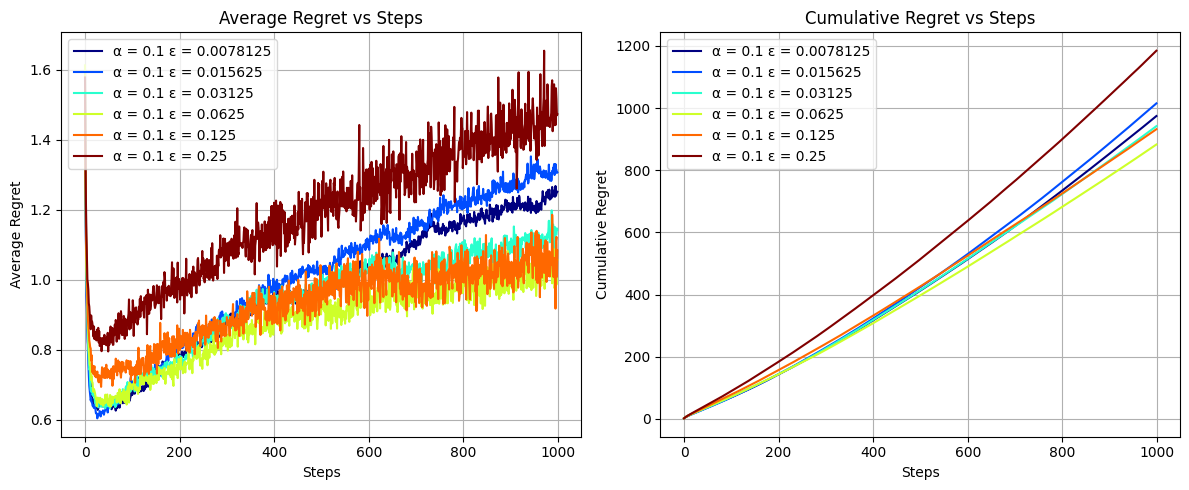

Rodando UCB...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Run 58/2000
Run 59/2000
Run 60/2000
Run 61/2000
Run 62/2000
Run 63/2000
Run 64/2000
Run 65/2000
Run 66/2000
Run 67/2000
Run 68/2000
Run 69/2000
Run 70/2000
Run 71/2000
Run 72/2000
Run 73/2000
Run 74/2000
Run 75/2000
Run 76/2000
Run 77/2000
Run 78/2000
Run 79/2000
Run 80/2000
Run 81/2000
Run 82/2000
Run 83/200

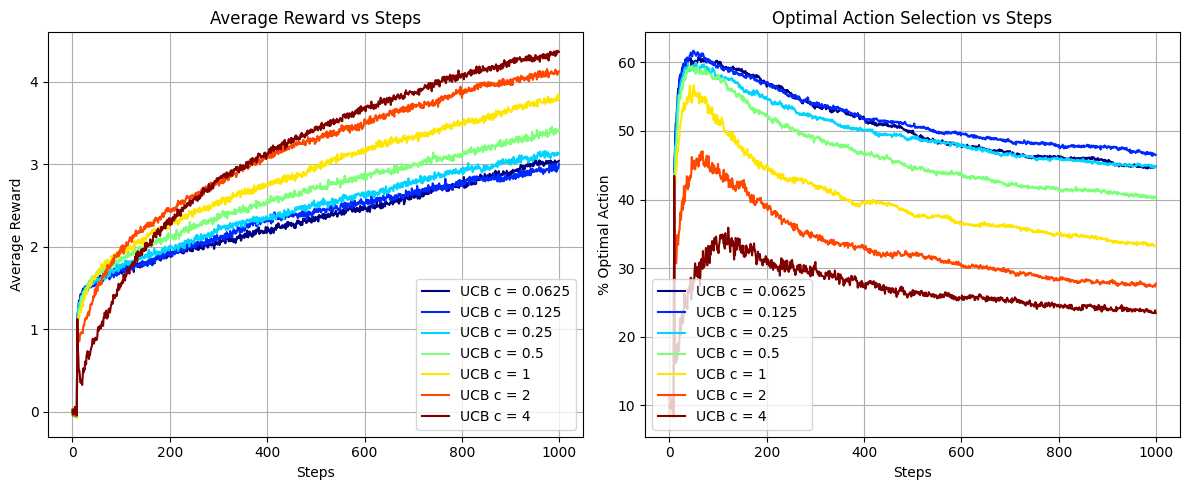

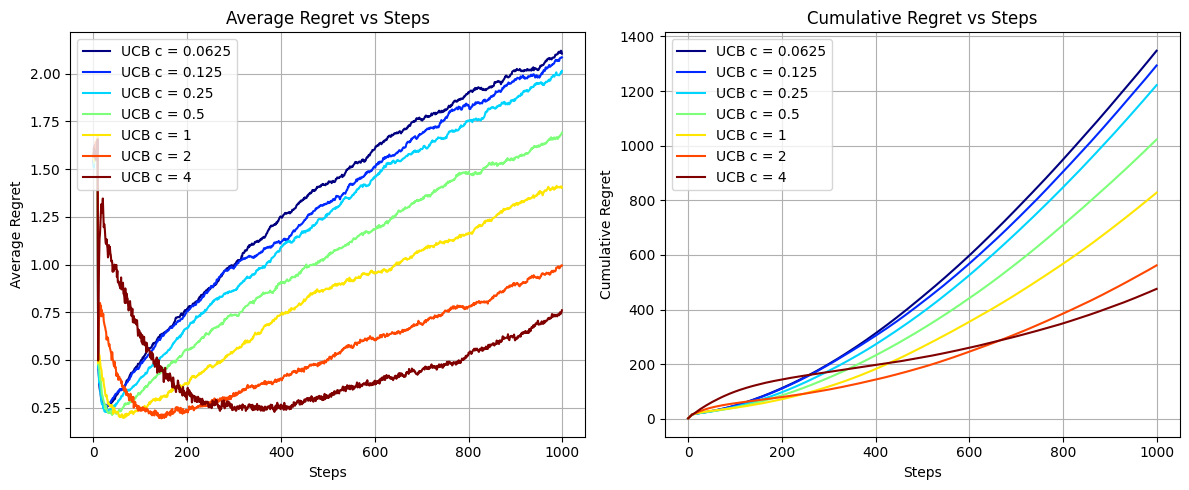

Rodando Optimistic Initialization...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Run 58/2000
Run 59/2000
Run 60/2000
Run 61/2000
Run 62/2000
Run 63/2000
Run 64/2000
Run 65/2000
Run 66/2000
Run 67/2000
Run 68/2000
Run 69/2000
Run 70/2000
Run 71/2000
Run 72/2000
Run 73/2000
Run 74/2000
Run 75/2000
Run 76/2000
Run 77/2000
Run 78/2000
Run 79/2000
Run 80/2000
Run 81/2000


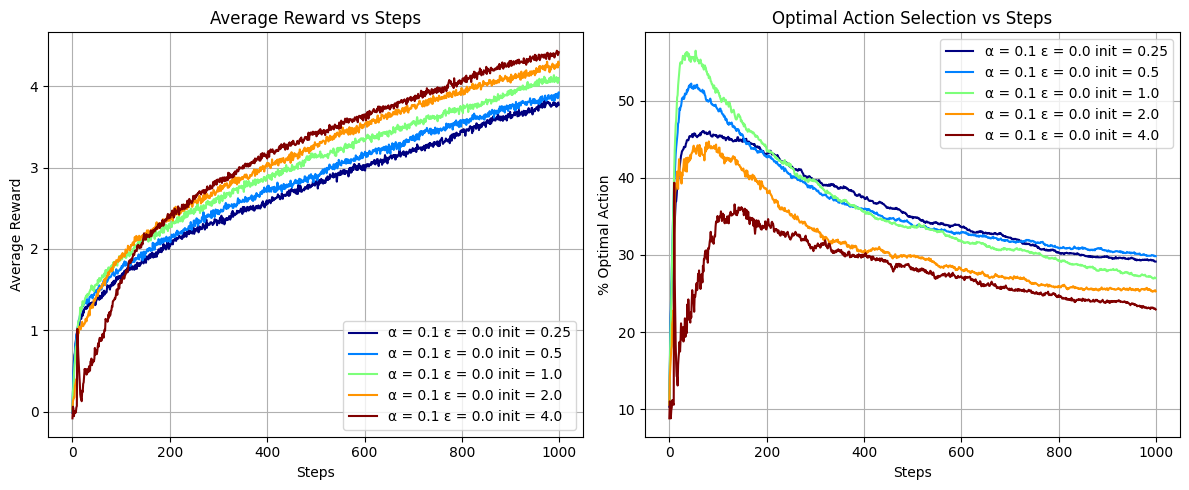

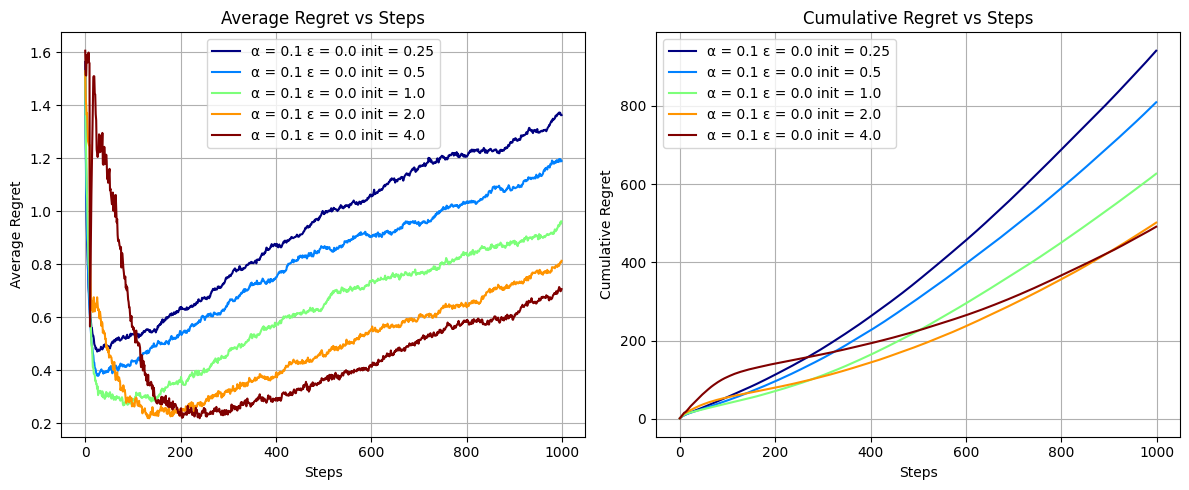

optimistic_Param: [0.25, 0.5, 1.0, 2.0, 4.0]
optimistic_rewards: [2.71549862 2.82629289 2.99132203 3.11591834 3.151818  ]
Rodando Gradient Bandit...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Run 58/2000
Run 59/2000
Run 60/2000
Run 61/2000
Run 62/2000
Run 63/2000
Run 64/2000
Run 65/2000
Run 66/2000
Run 67/2000
Run 68/2000
Run 69/2000
Run 70/2000
Run 71/2000
Run 72/2

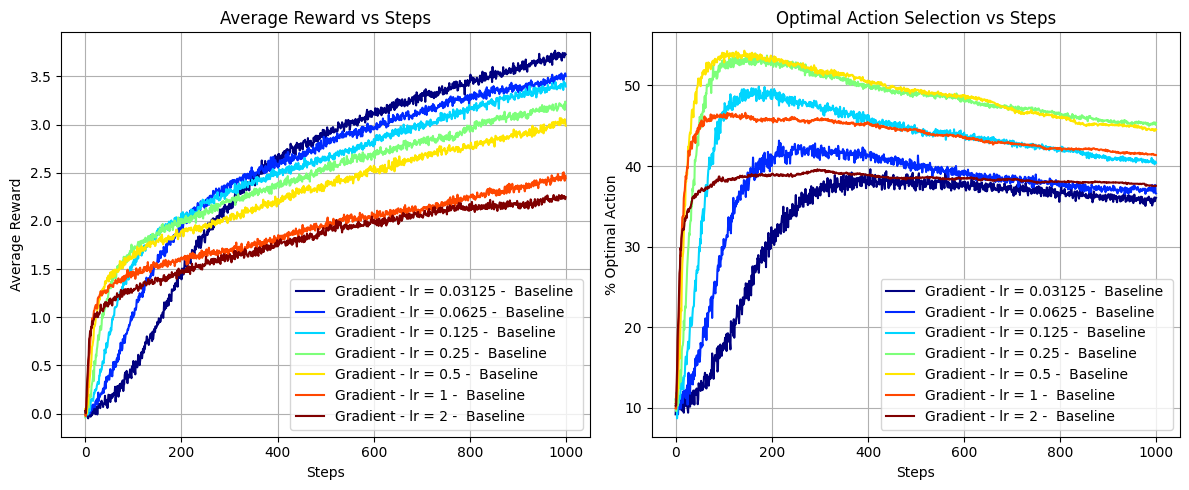

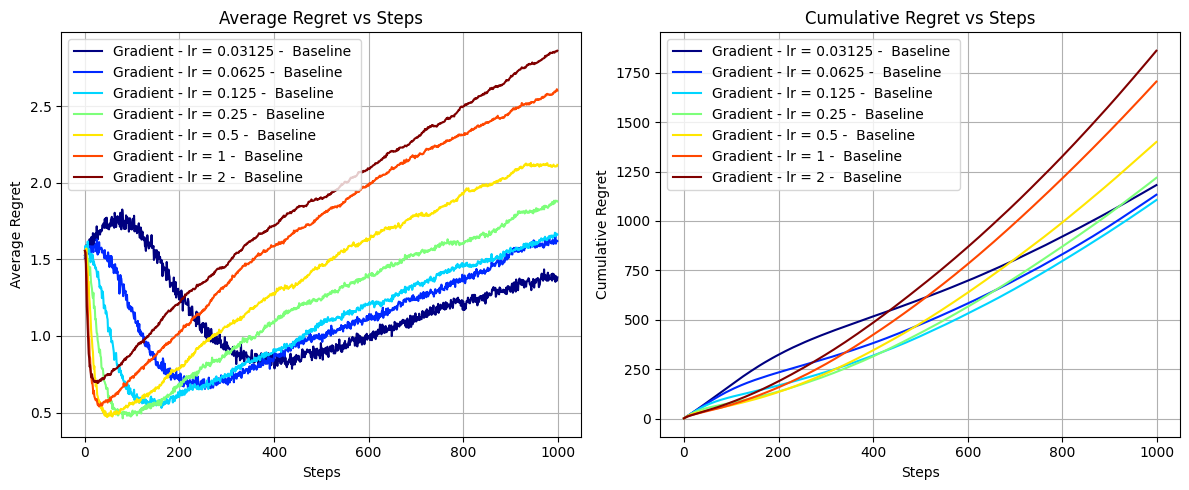

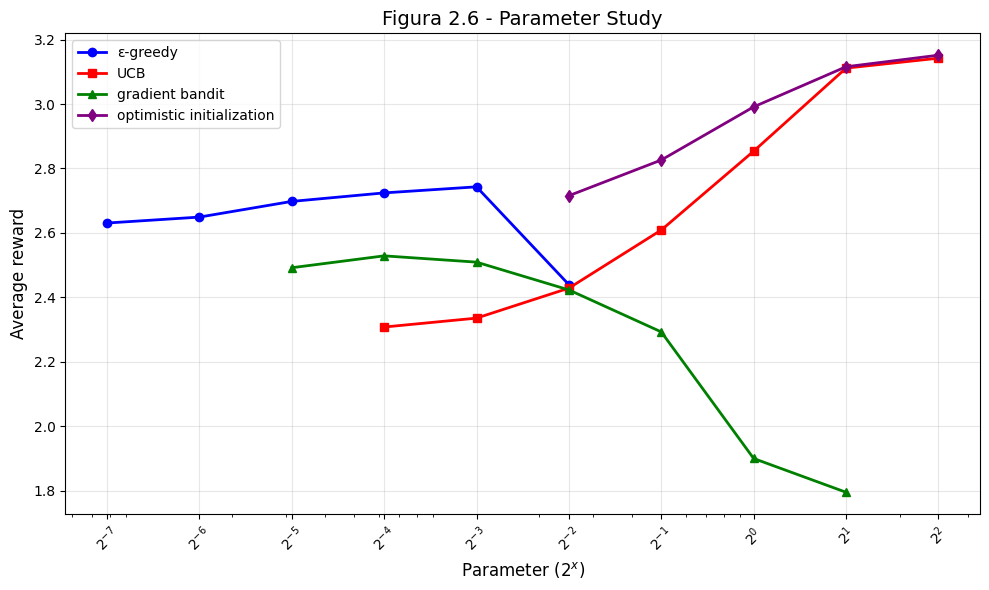

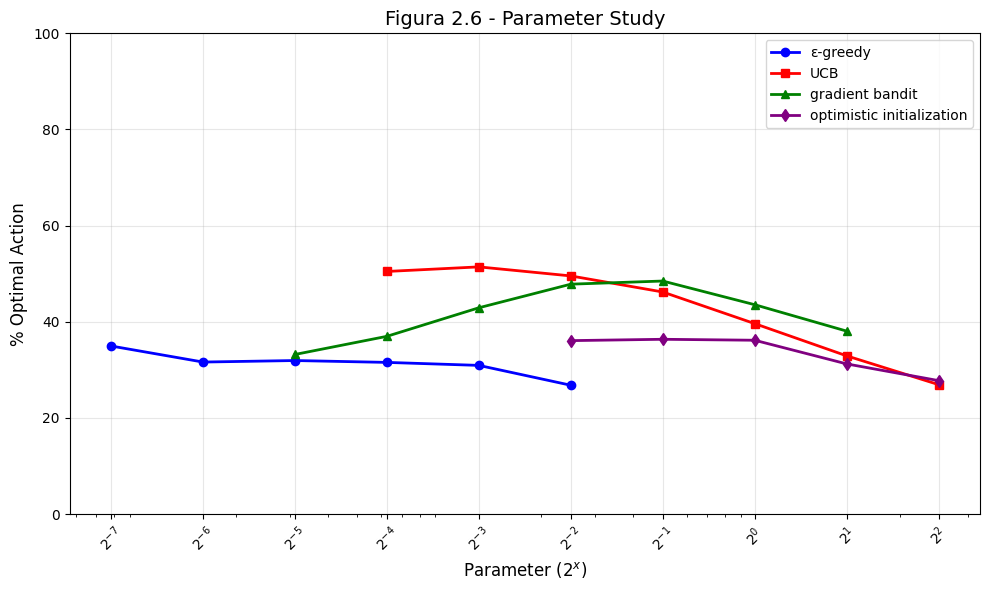

In [ ]:
# Caso de Teste - Exercise 2.11 pg 44 do Sutton & Barto - Comparação de Algoritmos para Ambiente Não Estacionário
mean_eps, mean_ucb, mean_opt, mean_grad, epsilon_Param, ucb_Param, optimin_Param, gradient_Param = ComparativeRangeEvaluation(stationary_env = False)

In [ ]:
# ============================================
# PRINT DOS VALORES NUMÉRICOS
# ============================================
print("\n" + "=" * 60)
print("RESULTADOS NUMÉRICOS (Média sobre tempo)")
print("=" * 60)

print("\nε-greedy:")
for p, r in zip(epsilon_Param, mean_eps):
    print(f"  {p:6.4f} (2^{int(np.log2(p)):2d}): {r:.4f}")

print("\nUCB:")
for p, r in zip(ucb_Param, mean_ucb):
    print(f"  {p:6.4f} (2^{int(np.log2(p)):2d}): {r:.4f}")

print("\nGradient Bandit:")
for p, r in zip(gradient_Param, mean_grad):
    print(f"  {p:6.4f} (2^{int(np.log2(p)):2d}): {r:.4f}")

print("\nOptimistic Initialization:")
for p, r in zip(optimin_Param, mean_opt):
    print(f"  {p:6.4f} (2^{int(np.log2(p)):2d}): {r:.4f}")


RESULTADOS NUMÉRICOS (Média sobre tempo)

ε-greedy:
  0.0078 (2^-7): 2.6306
  0.0156 (2^-6): 2.6491
  0.0312 (2^-5): 2.6977
  0.0625 (2^-4): 2.7242
  0.1250 (2^-3): 2.7430
  0.2500 (2^-2): 2.4392

UCB:
  0.0625 (2^-4): 2.3076
  0.1250 (2^-3): 2.3353
  0.2500 (2^-2): 2.4284
  0.5000 (2^-1): 2.6088
  1.0000 (2^ 0): 2.8537
  2.0000 (2^ 1): 3.1117
  4.0000 (2^ 2): 3.1425

Gradient Bandit:
  0.0312 (2^-5): 2.4918
  0.0625 (2^-4): 2.5287
  0.1250 (2^-3): 2.5092
  0.2500 (2^-2): 2.4229
  0.5000 (2^-1): 2.2925
  1.0000 (2^ 0): 1.8994
  2.0000 (2^ 1): 1.7945

Optimistic Initialization:
  0.2500 (2^-2): 2.7155
  0.5000 (2^-1): 2.8263
  1.0000 (2^ 0): 2.9913
  2.0000 (2^ 1): 3.1159
  4.0000 (2^ 2): 3.1518


In [ ]:
def ComparativeAlphaRangeEvaluation(stationary_env = True, num_runs = 2000, num_steps = 1000, Param_exp_range = (-7, 3), alpha_range = (0, 6)):
  # ============================================
  # CONFIGURAÇÕES GERAIS
  # ============================================
  media = 0

  if stationary_env:
    env = StationaryKBanditEnv(media_q_true=media)
  else:
    env = NonStationaryKBanditEnv(sigma_non_stationary=0.1)

  # Definição dos parâmetros (como no código oficial)
  Param = [2**i for i in range (Param_exp_range[0], Param_exp_range[1])]

  # Intervalos para cada algoritmo (como no livro)
  alpha_Param = Param[alpha_range[0]:alpha_range[1]]  # [1/128, 1/64, 1/32, 1/16, 1/8, 1/4]


  print("=" * 50)
  print("PARÂMETROS UTILIZADOS")
  print("=" * 50)
  print(f"α-greedy:     {[f'{p:.4f}' for p in alpha_Param]}")

  # ============================================
  # 1. PURE GREEDY (ε=0 COM VARIAÇÃO DE α)
  # ============================================
  print("\nRodando greedy pure...")
  #env = StationaryKBanditEnv()
  eps = 0.0
  if stationary_env:
    agents = [AgentAlpha(env, alpha=alpha, epsilon=eps) for alpha in alpha_Param]
  else:
    agents = [AgentAlpha(env, alpha=alpha, epsilon=eps) for alpha in alpha_Param]

  eval = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose=True)
  avg_rewards_pure_greedy, optimal_actions_pure_greedy, _, _ = eval.run()
  mean_pure_greedy = np.mean(avg_rewards_pure_greedy, axis=1)
  mean_oa_pure_greedy = 100.0*np.mean(optimal_actions_pure_greedy, axis=1)

  # ============================================
  # 2. EPSILON-GREEDY (ε=0.1 COM VARIAÇÃO DE α)
  # ============================================
  print("\nRodando ε-greedy...")
  #env = StationaryKBanditEnv()
  eps = 0.1
  if stationary_env:
    agents = [AgentAlpha(env, alpha=alpha, epsilon=eps) for alpha in alpha_Param]
  else:
    agents = [AgentAlpha(env, alpha=alpha, epsilon=eps) for alpha in alpha_Param]

  eval = EvaluateKBanditAgents(agents, env, num_runs, num_steps, verbose=True)
  avg_rewards_alfa_greedy, optimal_actions_alfa_greedy, _, _ = eval.run()
  mean_alfa_greedy = np.mean(avg_rewards_alfa_greedy, axis=1)
  mean_oa_alfa_greedy = 100.0*np.mean(optimal_actions_alfa_greedy, axis=1)


  # ============================================
  # PLOT DAS 2 CURVAS JUNTAS
  # ============================================
  def format_as_power(x):
      exponent = int(np.log2(x))
      return f'$2^{{{exponent}}}$'

  plt.figure(figsize=(10, 6))

  # Curva 1: pure greedy
  plt.semilogx(alpha_Param, mean_pure_greedy, 'o-', linewidth=2, markersize=6,
              label='pure greedy', color='blue')

  # Curva 2: ε-greedy
  plt.semilogx(alpha_Param, mean_alfa_greedy, 's-', linewidth=2, markersize=6,
              label='ε-greedy', color='red')

  # Configurações do gráfico
  plt.gca().set_xscale('log')
  plt.xlabel('Parameter ($2^x$)', fontsize=12)
  plt.ylabel('Average reward', fontsize=12)
  plt.title('Ambiente Não Estacionário - Aumentando ', fontsize=14)
  plt.legend(loc='best', fontsize=10)
  plt.grid(True, alpha=0.3)
  if stationary_env:
      plt.ylim(1.0, 1.5)  # Escala como no livro para ambiente estacionário


  # Configurar ticks do eixo X (unificar os parâmetros)
  # all_params = sorted(set(epsilon_Param + ucb_Param + gradient_Param + optimin_Param))
  xtick_labels = [format_as_power(p) for p in alpha_Param]
  plt.xticks(alpha_Param, xtick_labels, rotation=45)

  plt.tight_layout()
  plt.show()

  # ============================================
  # PLOT DAS 2 CURVAS JUNTAS (% OPTIMAL)
  # ============================================

  plt.figure(figsize=(10, 6))

  # Curva 1: pure greedy
  plt.semilogx(alpha_Param, mean_oa_pure_greedy, 'o-', linewidth=2, markersize=6,
              label='pure greedy', color='blue')

  # Curva 2: ε-greedy
  plt.semilogx(alpha_Param, mean_oa_alfa_greedy, 's-', linewidth=2, markersize=6,
              label='ε-greedy', color='red')

  # Configurações do gráfico
  plt.gca().set_xscale('log')
  plt.xlabel('α ($2^x$)', fontsize=12)
  plt.ylabel('% Optimal Action', fontsize=12)
  plt.title('Ambiente Não Estacionário', fontsize=14)
  plt.legend(loc='best', fontsize=10)
  plt.grid(True, alpha=0.3)
  plt.ylim(0.0, 100.0)



  # Configurar ticks do eixo X (unificar os parâmetros)
  # all_params = sorted(set(epsilon_Param + ucb_Param + gradient_Param + optimin_Param))
  xtick_labels = [format_as_power(p) for p in alpha_Param]
  plt.xticks(alpha_Param, xtick_labels, rotation=45)

  plt.tight_layout()
  plt.show()

  return mean_pure_greedy, mean_alfa_greedy, alpha_Param

PARÂMETROS UTILIZADOS
α-greedy:     ['0.0078', '0.0156', '0.0312', '0.0625', '0.1250', '0.2500']

Rodando greedy pure...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Run 58/2000
Run 59/2000
Run 60/2000
Run 61/2000
Run 62/2000
Run 63/2000
Run 64/2000
Run 65/2000
Run 66/2000
Run 67/2000
Run 68/2000
Run 69/2000
Run 70/2000
Run 71/2000
Run 72/2000
Run 73/2000
Run 74/2000


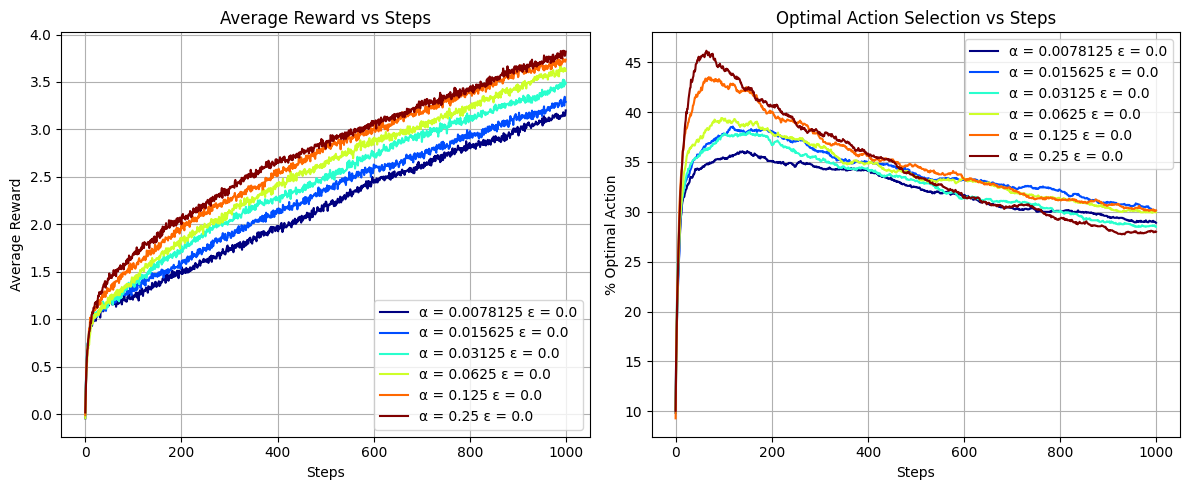

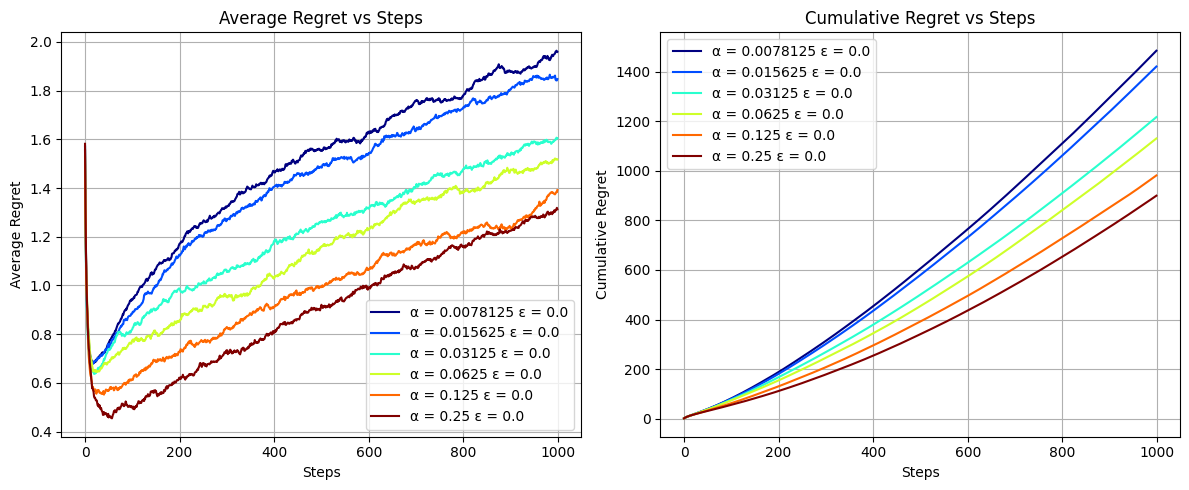


Rodando ε-greedy...
Run 1/2000
Run 2/2000
Run 3/2000
Run 4/2000
Run 5/2000
Run 6/2000
Run 7/2000
Run 8/2000
Run 9/2000
Run 10/2000
Run 11/2000
Run 12/2000
Run 13/2000
Run 14/2000
Run 15/2000
Run 16/2000
Run 17/2000
Run 18/2000
Run 19/2000
Run 20/2000
Run 21/2000
Run 22/2000
Run 23/2000
Run 24/2000
Run 25/2000
Run 26/2000
Run 27/2000
Run 28/2000
Run 29/2000
Run 30/2000
Run 31/2000
Run 32/2000
Run 33/2000
Run 34/2000
Run 35/2000
Run 36/2000
Run 37/2000
Run 38/2000
Run 39/2000
Run 40/2000
Run 41/2000
Run 42/2000
Run 43/2000
Run 44/2000
Run 45/2000
Run 46/2000
Run 47/2000
Run 48/2000
Run 49/2000
Run 50/2000
Run 51/2000
Run 52/2000
Run 53/2000
Run 54/2000
Run 55/2000
Run 56/2000
Run 57/2000
Run 58/2000
Run 59/2000
Run 60/2000
Run 61/2000
Run 62/2000
Run 63/2000
Run 64/2000
Run 65/2000
Run 66/2000
Run 67/2000
Run 68/2000
Run 69/2000
Run 70/2000
Run 71/2000
Run 72/2000
Run 73/2000
Run 74/2000
Run 75/2000
Run 76/2000
Run 77/2000
Run 78/2000
Run 79/2000
Run 80/2000
Run 81/2000
Run 82/2000
Run 

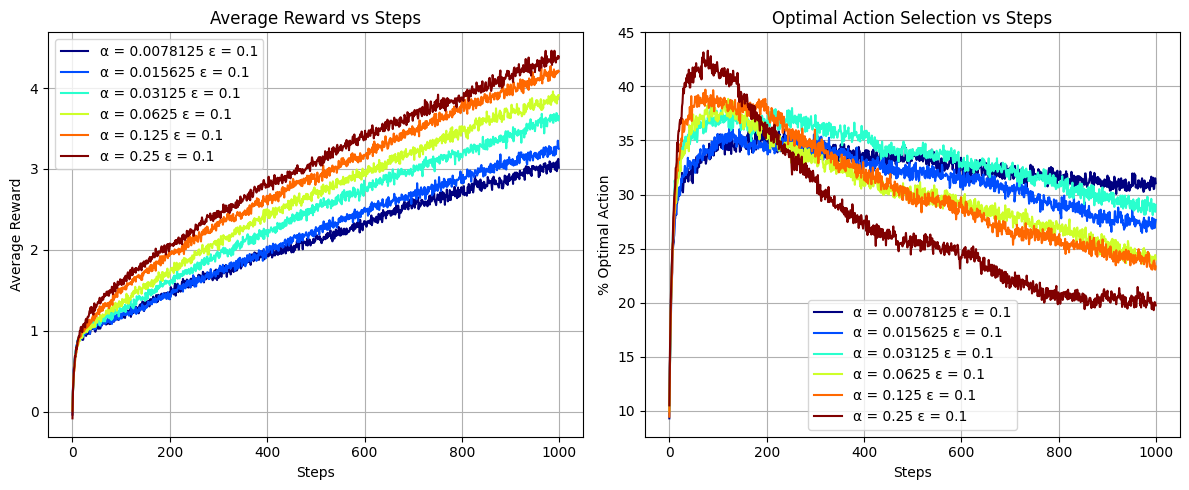

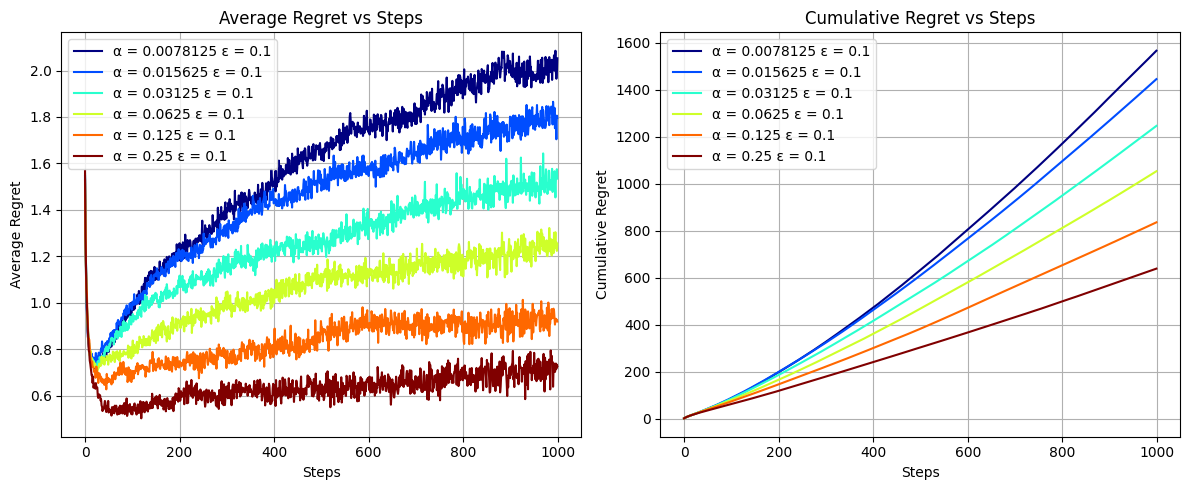

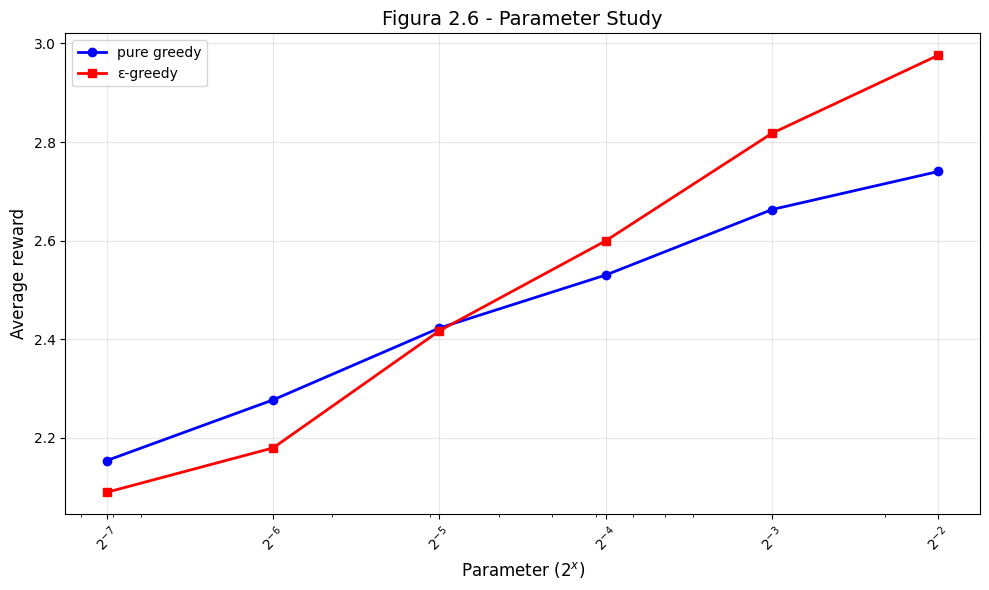

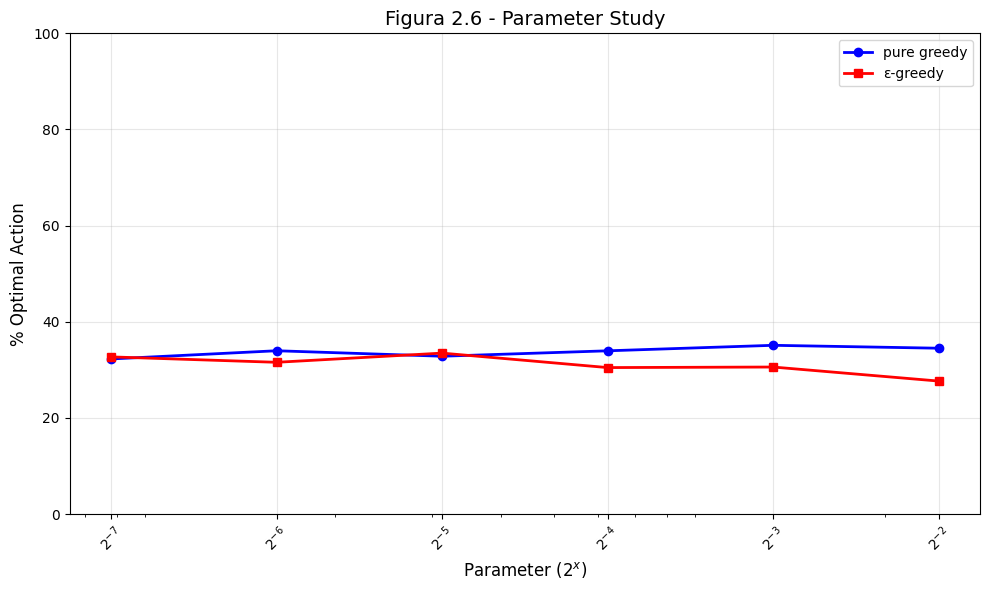

In [ ]:
mean_pure_greedy, mean_alfa_greedy, alpha_Param = ComparativeAlphaRangeEvaluation(stationary_env = False)

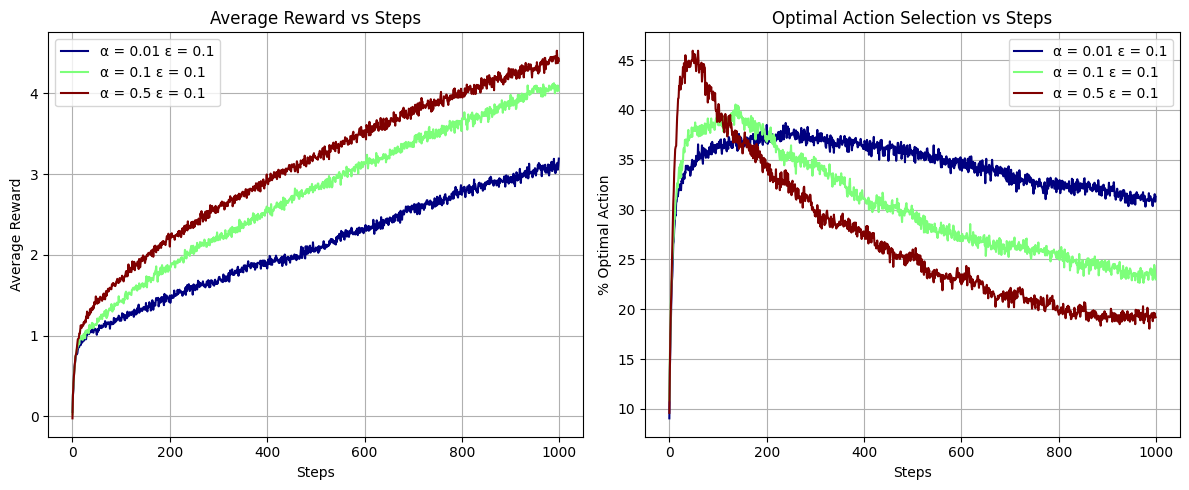

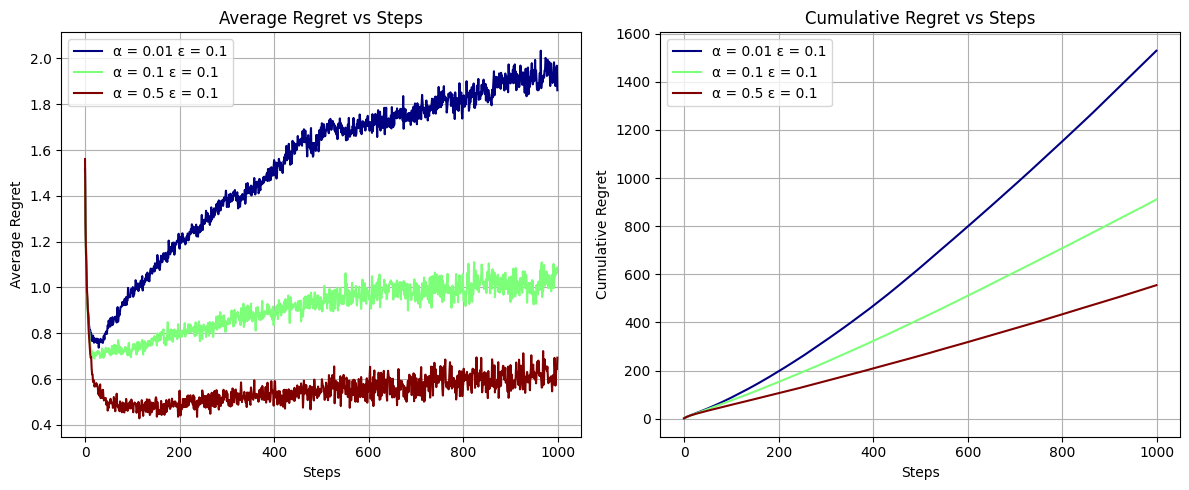

In [9]:
# Variando alpha para o ambiente Não Estacionário
env = NonStationaryKBanditEnv(sigma_non_stationary=0.1)
alpha_values = [0.01, 0.1, 0.5]
epsilon = 0.1 # Changed from [0.1] to 0.1
num_runs = 2000
num_steps = 1000

agents_alpha = []
for alpha in alpha_values:
  agents_alpha.append(AgentAlpha(env, alpha, epsilon))

eval_alpha = EvaluateKBanditAgents(agents_alpha, env, num_runs, num_steps, verbose = False)
results_alpha = eval_alpha.run()
